# Personalized TED Talk Recommendation System
## Exploratory Data Analysis (EDA) Notebook

**Project:** Personalized TED Talks Recommendation System Using Machine Learning  
**Stage:** Exploratory Data Analysis (before any model is built)  
**Input:** `ted_talks_cleaned.csv` (already cleaned by `ted_cleaning_eda.py`)

### Purpose of this notebook
1. Understand what the cleaned dataset contains.
2. Check data quality honestly (a dataset with no `NaN` values is **not** automatically perfect).
3. Study popularity, duration, publication time and topics.
4. Inspect the text fields (title, description, topics, transcript) and show how they can be combined into one
   `combined_text` field for a **content-based** recommender.

### What this notebook does *not* do
- It does **not** modify or overwrite `ted_talks_cleaned.csv`. The prepared dataset is saved as a **new** file (`ted_talks_prepared.csv`, Section 12).
- It does **not** train a model or implement TF-IDF (that belongs to the next stage).
- It does **not** invent ratings, user histories or any other data.

### Contents
1. Setup and loading the data  
2. Dataset overview  
3. Data-quality analysis  
4. Univariate analysis (views, top talks, duration, years, transcripts, comments, dates)  
5. Topic analysis  
6. Speaker analysis  
7. Language analysis  
8. Event and occupation analysis  
9. Related talks analysis  
10. Bivariate analysis (relationships)  
11. Text analysis (for the content-based recommender)  
12. Data cleaning and preparation (creates `ted_talks_prepared.csv`)  
13. Findings, limitations and conclusions  
14. Final EDA summary and completion checklist  


> All numbers in the findings are **calculated when the notebook runs**, so they always match the data you load.

## 1. Setup and loading the data

**Libraries used:** `pandas` (tables), `numpy` (numbers), `matplotlib` and `seaborn` (charts).  
**Run in VS Code:** open this notebook, choose a Python kernel, put `ted_talks_cleaned.csv` in the same folder, *Run All*.  
**Run in Google Colab:** upload this notebook; when the loading cell cannot find the CSV it will open an **upload button** so you can pick `ted_talks_cleaned.csv`
(or mount Google Drive and place the file in *My Drive*).

Required libraries (already installed in Colab): `pip install pandas numpy matplotlib seaborn`

**Status: COMPLETED**

In [1]:
# ---- Imports -------------------------------------------------------------
import hashlib
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
warnings.filterwarnings("ignore")

# ---- Global style so every chart looks consistent ---------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13,
                     "axes.titleweight": "bold", "axes.labelsize": 11})
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
# ---- Locate the CSV (works in VS Code, Jupyter and Google Colab) ------------------
CSV_NAME = "ted_talks_cleaned.csv"
search_places = [Path(CSV_NAME), Path("data") / CSV_NAME, Path("..") / CSV_NAME,
                 Path("/content") / CSV_NAME, Path("/content/drive/MyDrive") / CSV_NAME]
csv_path = next((p for p in search_places if p.exists()), None)

if csv_path is None:
    try:                                   # only works inside Google Colab
        from google.colab import files
        print(f"'{CSV_NAME}' not found. Please upload it now:")
        uploaded = files.upload()
        csv_path = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            f"Could not find '{CSV_NAME}'. Put it in the same folder as this notebook "
            "(or in a 'data' sub-folder) and run this cell again.")


def file_fingerprint(path):
    """SHA-256 fingerprint. Compared at the end to prove the CSV was never changed."""
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


FINGERPRINT_BEFORE = file_fingerprint(csv_path)

# ---- Load (read-only) -----------------------------------------------------------
df = pd.read_csv(csv_path)
for c in ["recorded_date", "published_date"]:          # turn date text into real dates
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

ORIG_COLS = list(df.columns)   # the columns that are really in the CSV (before any helper column is added)
print(f"Loaded: {csv_path}")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")

Loaded: ted_talks_cleaned.csv
Rows: 4,005   Columns: 37


In [3]:
# ---- Small helper functions used throughout the notebook ------------------------------------
def has_cols(*cols):
    """True if all columns exist. Otherwise print a warning so the notebook never crashes."""
    missing = [c for c in cols if c not in df.columns]
    if missing:
        print(f"Skipped: column(s) {missing} not found in the dataset.")
    return not missing


def is_blank(series):
    """True for NaN or text that is empty / only spaces."""
    return series.isna() | series.astype(str).str.strip().eq("")


def pct(part, whole):
    return round(100 * part / whole, 1) if whole else 0.0


def binned_median(x, y, q=10):
    """Split x into q equal-size groups and return the median x and y of every group (trend line)."""
    tmp = pd.DataFrame({"x": x, "y": y}).dropna()
    groups = pd.qcut(tmp["x"], q=q, duplicates="drop")
    return tmp.groupby(groups, observed=True).median()


# ---- Analysis-only helper columns (created in memory; the CSV file is NOT changed) ----------------
if "duration_min" not in df.columns and "duration" in df.columns:
    df["duration_min"] = df["duration"] / 60
if "published_year" not in df.columns and "published_date" in df.columns:
    df["published_year"] = df["published_date"].dt.year
if "transcript_word_count" not in df.columns and "transcript" in df.columns:
    df["transcript_word_count"] = df["transcript"].fillna("").astype(str).str.split().str.len()
if "views" in df.columns:
    df["log10_views"] = np.log10(df["views"] + 1)           # log scale: easier to read skewed data
if has_cols("comments", "comments_missing"):
    # comments == 0 may mean "no data" (filled during cleaning). Keep only REAL comment counts:
    df["comments_real"] = df["comments"].where(~df["comments_missing"].astype(bool))
    df["log10_comments_real"] = np.log10(df["comments_real"] + 1)
elif "comments" in df.columns:
    df["comments_real"] = df["comments"].astype(float)
    df["log10_comments_real"] = np.log10(df["comments_real"] + 1)

N = len(df)
print("Helper functions and analysis columns ready.")

Helper functions and analysis columns ready.


## 2. Dataset overview
First we look at the raw shape of the data: first and last records, dimensions, column names, data types
and summary statistics. (The long `transcript` column is shortened so the output stays readable.)

**Status: COMPLETED**

In [4]:
# First 5 and last 5 records (text columns shortened for readability)
preview_cols = [c for c in ["talk_id", "title", "speaker_1", "event", "views", "published_date",
                            "duration_min", "topics"] if c in df.columns]
preview = df[preview_cols].copy()
for c in ["title", "topics"]:
    if c in preview:
        preview[c] = preview[c].astype(str).str.slice(0, 55)

print("FIRST 5 RECORDS")
display(preview.head(5))
print("LAST 5 RECORDS")
display(preview.tail(5))

FIRST 5 RECORDS


,talk_id,title,speaker_1,event,views,published_date,duration_min,topics
0,1,Averting the climate crisis,Al Gore,TED2006,3523392,2006-06-27,16.28,alternative energy | cars | climate change | culture |
1,92,The best stats you've ever seen,Hans Rosling,TED2006,14501685,2006-06-27,19.83,africa | asia | google | demo | economics | global issu
2,7,Simplicity sells,David Pogue,TED2006,1920832,2006-06-27,21.43,computers | entertainment | interface design | media |
3,53,Greening the ghetto,Majora Carter,TED2006,2664069,2006-06-27,18.60,macarthur grant | activism | business | cities | enviro
4,66,Do schools kill creativity?,Sir Ken Robinson,TED2006,65051954,2006-06-27,19.40,children | creativity | culture | dance | education | p


LAST 5 RECORDS


,talk_id,title,speaker_1,event,views,published_date,duration_min,topics
4000,62678,"Crisis support for the world, one text away",Nancy Lublin,TED2020: The Prequel,502934,2020-04-27,11.50,activism | data | technology | mental health | software
4001,62782,The dark history of IQ tests,Stefan C Dombrowski,TED-Ed,307187,2020-04-27,5.77,ted-ed | education | history | animation | intelligence
4002,62263,"How ""policing for profit"" undermines your rights",Dick M. Carpenter II,TEDxMileHigh,464414,2020-04-28,12.90,society | law | policy | justice system | tedx
4003,62784,The electrifying speeches of Sojourner Truth,Daina Ramey Berry,TED-Ed,56582,2020-04-30,4.28,ted-ed | education | animation | united states | women
4004,62794,The most important anus in the ocean,Cella Wright,TED-Ed,0,2020-04-30,4.68,animals | ted-ed | animation | oceans | science | educa


In [5]:
# Dimensions, column names and data types
base = df[ORIG_COLS]            # only the columns of the original file
print(f"Dimensions: {base.shape[0]:,} rows x {base.shape[1]} columns\n")
schema = pd.DataFrame({"dtype": base.dtypes.astype(str), "non_null": base.notna().sum(),
                       "unique_values": base.nunique()})
display(schema)

Dimensions: 4,005 rows x 37 columns



,dtype,non_null,unique_values
talk_id,int64,4005,4005
title,str,4005,4005
speaker_1,str,4005,3274
all_speakers,str,4005,3310
occupations,str,4005,2027
about_speakers,str,4005,2978
views,int64,4005,3996
recorded_date,datetime64[us],4005,1334
published_date,datetime64[us],4005,2962
event,str,4005,459


In [6]:
# Summary statistics for numeric columns (talk_id is only an identifier, so it is left out)
numeric_cols = [c for c in df[ORIG_COLS].select_dtypes("number").columns if c not in ("talk_id",)]
display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
views,"4,005.00","2,148,005.57","3,451,225.52",0.00,"882,069.00","1,375,508.00","2,133,110.00","65,051,954.00"
comments,"4,005.00",135.50,253.07,0.00,17.00,68.00,162.00,"6,449.00"
duration,"4,005.00",724.01,361.78,60.00,393.00,738.00,974.00,"3,922.00"
num_speakers,"4,005.00",1.03,0.22,1.00,1.00,1.00,1.00,5.00
num_languages,"4,005.00",25.30,9.04,1.00,20.00,25.00,31.00,73.00
num_topics,"4,005.00",7.92,3.90,1.00,5.00,7.00,10.00,33.00
duration_min,"4,005.00",12.07,6.03,1.00,6.55,12.30,16.23,65.37
recorded_year,"4,005.00","2,013.76",4.17,"1,984.00","2,011.00","2,014.00","2,017.00","2,020.00"
published_year,"4,005.00","2,014.60",3.99,"2,006.00","2,011.00","2,015.00","2,018.00","2,020.00"
published_month,"4,005.00",6.13,3.47,1.00,3.00,6.00,9.00,12.00


### 2.1 Meaning and usefulness of the main columns
The table below is built from the columns that really exist in your file.

In [7]:
column_guide = {
    "talk_id": ("Unique numeric ID of the talk", "Key to identify a talk and match 'related talks'"),
    "title": ("Title of the talk", "Short, information-rich text for content-based similarity"),
    "speaker_1": ("Main speaker", "Display/filter; 'more from this speaker'"),
    "all_speakers": ("All speakers (separated by |)", "Multi-speaker talks; speaker features"),
    "occupations": ("Speaker occupation(s), separated by |", "Hints at the field of expertise"),
    "about_speakers": ("Speaker biography text", "Extra text about the speaker's background"),
    "views": ("Total number of views", "Popularity signal"),
    "recorded_date": ("Date the talk was recorded", "Time context of the talk"),
    "published_date": ("Date the talk went online", "Recency; time-based splitting"),
    "event": ("TED event where the talk was given", "Context (year, theme, audience)"),
    "native_lang": ("Language spoken in the talk", "Language filter"),
    "available_lang": ("Subtitle languages (separated by |)", "Reach / language availability"),
    "comments": ("Number of comments (0 may be a filled-in value, see comments_missing)", "Engagement signal - use with care"),
    "duration": ("Length in seconds", "Short vs long talk preference"),
    "topics": ("Topic tags separated by |", "Core feature for content-based recommendation"),
    "related_talks": ("Titles of related talks listed by TED", "Possible reference for later evaluation"),
    "url": ("Link to the talk", "Link shown to the user"),
    "description": ("Short summary of the talk", "Clean, concise text for similarity"),
    "transcript": ("Full spoken text", "Richest content source for similarity"),
    "recorded_date_imputed": ("Flag: recorded date was filled from the published date", "Marks substituted values"),
    "num_speakers": ("Number of speakers", "Derived feature"),
    "num_languages": ("Number of languages available", "Possible reach/popularity proxy"),
    "num_topics": ("Number of topic tags", "Derived feature"),
    "related_talk_ids": ("IDs of related talks listed by TED", "Possible reference for later evaluation"),
    "comments_missing": ("Flag: comments were missing and filled with 0", "Separates real zeros from filled zeros"),
    "views_zero_flag": ("Flag: talk has 0 views", "Marks unusual popularity values"),
    "duration_min": ("Duration in minutes", "Easier to read than seconds"),
    "recorded_year": ("Year recorded", "Time feature"),
    "published_year": ("Year published", "Time feature"),
    "published_month": ("Month published", "Seasonality feature"),
    "talk_age_days": ("Days between publishing and dataset end", "Age of the talk"),
    "log_views": ("log(1 + views)", "Reduces the skew of views"),
    "views_per_day": ("views / talk_age_days", "Popularity relative to age (use with care)"),
    "transcript_word_count": ("Number of words in the transcript", "Text length"),
    "words_per_minute": ("Transcript words / duration (minutes)", "Speaking pace; quality check"),
    "event_type": ("Event name with years/numbers removed", "Grouped event information"),
    "views_outlier": ("Flag: views are unusually high (IQR rule)", "Marks extreme popularity"),
}
guide = pd.DataFrame(
    [(c, str(df[c].dtype), *column_guide.get(c, ("(no description written)", ""))) for c in ORIG_COLS],
    columns=["column", "dtype", "meaning", "usefulness for the recommender"])
display(guide)

,column,dtype,meaning,usefulness for the recommender
0,talk_id,int64,Unique numeric ID of the talk,Key to identify a talk and match 'related talks'
1,title,str,Title of the talk,"Short, information-rich text for content-based similarity"
2,speaker_1,str,Main speaker,Display/filter; 'more from this speaker'
3,all_speakers,str,All speakers (separated by |),Multi-speaker talks; speaker features
4,occupations,str,"Speaker occupation(s), separated by |",Hints at the field of expertise
5,about_speakers,str,Speaker biography text,Extra text about the speaker's background
6,views,int64,Total number of views,Popularity signal
7,recorded_date,datetime64[us],Date the talk was recorded,Time context of the talk
8,published_date,datetime64[us],Date the talk went online,Recency; time-based splitting
9,event,str,TED event where the talk was given,"Context (year, theme, audience)"


## 3. Data-quality analysis
Cleaning removed all pandas-recognised missing values (`NaN`). But **"no NaN" does not mean "perfect data"**.
Values can still be:
- empty text (`""`), 
- placeholders such as `Unknown`, 
- zeros that were **substituted** during cleaning (not real zeros),
- unusual or suspicious values (impossible dates, extremely short transcripts, ...).

We therefore check all of these separately.

**Status: COMPLETED**

### 3.1 Missing values, empty text and duplicates

In [8]:
# 1) Pandas-recognised nulls (NaN / None)
total_nulls = int(df[ORIG_COLS].isna().sum().sum())
print(f"Total null cells recognised by pandas: {total_nulls}")

# 2) Empty or whitespace-only text in the important text columns
text_cols = [c for c in ["title", "description", "transcript", "topics", "speaker_1",
                         "about_speakers", "occupations", "event", "url"] if c in df.columns]
blank_report = pd.DataFrame({"null": df[text_cols].isna().sum(),
                             "empty_or_blank": df[text_cols].apply(is_blank).sum()})
display(blank_report)

# 3) Duplicates
dup_checks = {"duplicate rows (all columns)": int(df[ORIG_COLS].duplicated().sum())}
for c in ["talk_id", "url", "title"]:
    if c in df.columns:
        dup_checks[f"duplicate {c}"] = int(df[c].duplicated().sum())
display(pd.Series(dup_checks, name="count").to_frame())

Total null cells recognised by pandas: 0


,null,empty_or_blank
title,0,0
description,0,0
transcript,0,0
topics,0,0
speaker_1,0,0
about_speakers,0,0
occupations,0,0
event,0,0
url,0,0


,count
duplicate rows (all columns),0
duplicate talk_id,0
duplicate url,0
duplicate title,0


### 3.2 Placeholder values such as `Unknown`
We scan every text column for common placeholder words (exact matches after trimming spaces and ignoring case).

In [9]:
PLACEHOLDERS = {"unknown", "n/a", "na", "none", "null", "nan", "-", "--", "?", "tbd", "not available", "missing"}
rows = []
for col in ORIG_COLS:
    if (pd.api.types.is_numeric_dtype(df[col]) or pd.api.types.is_bool_dtype(df[col])
            or pd.api.types.is_datetime64_any_dtype(df[col])):
        continue                                             # placeholders only matter in text columns
    hits = df[col].notna() & df[col].astype(str).str.strip().str.lower().isin(PLACEHOLDERS)
    if hits.any():
        rows.append({"column": col, "placeholder_rows": int(hits.sum()), "percent_of_talks": pct(hits.sum(), N)})
placeholder_report = pd.DataFrame(rows)
if placeholder_report.empty:
    print("No placeholder values found.")
else:
    display(placeholder_report.sort_values("placeholder_rows", ascending=False).reset_index(drop=True))

,column,placeholder_rows,percent_of_talks
0,occupations,522,13.00
1,about_speakers,503,12.60


### 3.3 Zero values, substituted values and unusual values
**Key idea:** a `0` in `comments` can mean two different things:
1. the talk **really** has zero comments (genuine zero), or
2. comment data was **missing** and cleaning filled in `0` (substituted zero).
The flag column `comments_missing` lets us tell them apart.

In [10]:
# ---- Zero views ---------------------------------------------------------------
if has_cols("views"):
    zero_views = df[df["views"] == 0]
    print(f"Talks with 0 views: {len(zero_views)}")
    if len(zero_views):
        display(zero_views[[c for c in ["talk_id", "title", "speaker_1", "published_date"] if c in df.columns]])

# ---- Comments: genuine vs substituted zeros -----------------------------------------
if has_cols("comments", "comments_missing"):
    miss = df["comments_missing"].astype(bool)
    zero_c = df["comments"] == 0
    comments_table = pd.Series({
        "Talks with comments = 0 (total)": int(zero_c.sum()),
        "  of which SUBSTITUTED during cleaning (comments_missing = True)": int((zero_c & miss).sum()),
        "  of which GENUINE zero comments": int((zero_c & ~miss).sum()),
        "Talks with comments_missing = True": int(miss.sum()),
        "comments_missing = True but comments != 0 (should be 0)": int((miss & ~zero_c).sum()),
        "Talks with real comment data": int((~miss).sum()),
    }, name="count").to_frame()
    display(comments_table)

Talks with 0 views: 6


,talk_id,title,speaker_1,published_date
2813,17850,Por qué necesitamos proteger el alta mar,Enric Sala,2018-06-06
3056,29009,Cómo usar el arte de la fotografía para restaurar la memoria,Alejandro Chaskielberg,2018-11-29
3068,29688,Por qué deberíamos comer más bichos,Renata di Tullio,2018-12-07
3520,43755,Can dogs sniff out malaria?,James Logan,2019-06-11
3790,55342,¿Como será el cine del futuro?,Diego Prilusky,2019-12-19
4004,62794,The most important anus in the ocean,Cella Wright,2020-04-30


,count
Talks with comments = 0 (total),657
of which SUBSTITUTED during cleaning (comments_missing = True),655
of which GENUINE zero comments,2
Talks with comments_missing = True,655
comments_missing = True but comments != 0 (should be 0),0
Talks with real comment data,3350


In [11]:
# ---- Missing speaker information ---------------------------------------------------------
for col in ["about_speakers", "occupations"]:
    if has_cols(col):
        n_unknown = int((df[col].astype(str).str.strip().str.lower() == "unknown").sum())
        print(f"{col}: 'Unknown' for {n_unknown} talks ({pct(n_unknown, N)}%)")

# ---- Unusual durations ------------------------------------------------------------------------
if has_cols("duration_min"):
    d = df["duration_min"]
    q1, q3 = d.quantile([.25, .75])
    upper = q3 + 1.5 * (q3 - q1)
    print(f"\nDuration (minutes): min {d.min():.1f} | median {d.median():.1f} | max {d.max():.1f}")
    print(f"Talks longer than the IQR upper limit ({upper:.1f} min): {(d > upper).sum()}")
    cols = [c for c in ["title", "speaker_1", "duration_min"] if c in df.columns]
    print("\nShortest 5 talks:")
    display(df.nsmallest(5, "duration_min")[cols])
    print("Longest 5 talks:")
    display(df.nlargest(5, "duration_min")[cols])

# ---- Suspicious dates --------------------------------------------------------------------------
if has_cols("recorded_date", "published_date"):
    bad_order = int((df["recorded_date"] > df["published_date"]).sum())
    print(f"\nTalks recorded AFTER they were published (impossible order): {bad_order}")

# ---- Very short transcripts ----------------------------------------------------------------------
if has_cols("transcript_word_count"):
    short_tr = df[df["transcript_word_count"] < 50]
    print(f"Transcripts with fewer than 50 words: {len(short_tr)}")
    if len(short_tr):
        display(short_tr[[c for c in ["title", "speaker_1", "duration_min", "transcript_word_count"]
                          if c in df.columns]].head(10))

about_speakers: 'Unknown' for 503 talks (12.6%)
occupations: 'Unknown' for 522 talks (13.0%)

Duration (minutes): min 1.0 | median 12.3 | max 65.4
Talks longer than the IQR upper limit (30.8 min): 21

Shortest 5 talks:


,title,speaker_1,duration_min
3623,"""Ode to the Only Black Kid in the Class""",Clint Smith,1.00
3516,"""Three Months After""",Cristin O'Keefe Aptowicz,1.30
3554,"""New Colossus""",Emma Lazarus,1.30
2753,"""Illusions for a better society""",Aaron Duffy,1.78
3502,"""The Second Coming""",William Butler Yeats,1.82


Longest 5 talks:


,title,speaker_1,duration_min
3768,How we can turn the tide on climate,Chris Anderson,65.37
3965,The quest for the coronavirus vaccine,Seth Berkley,62.67
3973,It's OK to feel overwhelmed. Here's what to do next,Elizabeth Gilbert,62.33
2334,Nationalism vs. globalism: the new political divide,Yuval Noah Harari,60.13
3966,What the world can learn from China's response to the coronavirus,Gary Liu,58.38



Talks recorded AFTER they were published (impossible order): 17
Transcripts with fewer than 50 words: 10


,title,speaker_1,duration_min,transcript_word_count
145,My magic moves,Kenichi Ebina,3.53,3
303,Playing invisible turntables,James Burchfield,4.73,20
573,An all-star set,Herbie Hancock,25.08,25
904,"On violin and cello, ""Passacaglia""",Robert Gupta,9.35,4
1198,Dancing with light,Quixotic Fusion,12.37,8
1393,"Dance, tiny robots!",Bruno Maisonnier,3.15,4
1825,"A dance in a hurricane of paper, wind and light",Aakash Odedra,9.83,2
1948,An 11-year-old prodigy performs old-school jazz,Joey Alexander,6.47,4
2029,A musical escape into a world of light and color,Kaki King,11.52,19
2330,An electrifying acoustic guitar performance,Rodrigo y Gabriela,4.28,7


### 3.4 Existing cleaning flags
The cleaning script added flag columns to mark values it changed or found unusual.
We check how many talks each flag marks and whether the flags are consistent with the data.

In [12]:
flags = [c for c in ["comments_missing", "views_zero_flag", "recorded_date_imputed", "views_outlier"] if c in df.columns]
flag_table = pd.DataFrame({"talks_flagged": [int(df[f].astype(bool).sum()) for f in flags]}, index=flags)
flag_table["percent_of_talks"] = [pct(v, N) for v in flag_table["talks_flagged"]]
display(flag_table)

# Consistency checks: does each flag really match the data?
print("Consistency checks")
if has_cols("views_zero_flag", "views"):
    print(" - views_zero_flag matches (views == 0):", bool((df["views_zero_flag"].astype(bool) == (df["views"] == 0)).all()))
if has_cols("views_outlier", "views"):
    q1, q3 = df["views"].quantile([.25, .75])
    recomputed = df["views"] > q3 + 1.5 * (q3 - q1)
    same = bool((df["views_outlier"].astype(bool) == recomputed).all())
    print(" - views_outlier matches the 1.5 x IQR rule recomputed here:", same)
    print(f"   (views above {q3 + 1.5 * (q3 - q1):,.0f} are flagged; these are genuine very popular talks, not errors)")
if has_cols("recorded_date_imputed"):
    print(" - recorded_date_imputed talks:", int(df["recorded_date_imputed"].astype(bool).sum()),
          "(their recorded date is a substitute, not an observed value)")

,talks_flagged,percent_of_talks
comments_missing,655,16.40
views_zero_flag,6,0.10
recorded_date_imputed,1,0.00
views_outlier,393,9.80


Consistency checks
 - views_zero_flag matches (views == 0): True
 - views_outlier matches the 1.5 x IQR rule recomputed here: True
   (views above 4,009,672 are flagged; these are genuine very popular talks, not errors)
 - recorded_date_imputed talks: 1 (their recorded date is a substitute, not an observed value)


### 3.5 Cleaning log from the earlier cleaning step (optional)
If `cleaning_log.json` is next to this notebook, we display what the cleaning step recorded. This is only for reference.

In [13]:
log_path = next((p for p in [Path("cleaning_log.json"), Path("data/cleaning_log.json"), Path("../cleaning_log.json"),
                             Path("/content/cleaning_log.json")] if p.exists()), None)
if log_path is None:
    print("cleaning_log.json not found - skipping (this notebook does not need it).")
else:
    with open(log_path, encoding="utf-8") as fh:
        cleaning_log = json.load(fh)
    simple = {k: v for k, v in cleaning_log.items()
              if isinstance(v, (int, float, str, list)) and k not in ("sample_recommendations",)}
    display(pd.Series({k: str(v) for k, v in simple.items()}, name="value").to_frame())
    print("Values changed during cleaning are summarised above; raw_missing shows what was originally missing:")
    print(cleaning_log.get("raw_missing", "not recorded"))

,value
raw_shape,"[4005, 19]"
duplicate_rows,0
duplicate_talk_id,0
duplicate_url,0
duplicate_title,0
recorded_date_missing,1
recorded_after_published,17
all_speakers_missing_filled_from_speaker_1,4
occupations_missing,522
comments_missing,655


Values changed during cleaning are summarised above; raw_missing shows what was originally missing:
{'all_speakers': 4, 'occupations': 522, 'about_speakers': 503, 'recorded_date': 1, 'comments': 655}


### 3.6 Data-quality scorecard
One table that gathers the issues found above. The *Interpretation* column explains what each issue means.

In [14]:
def add(rows, issue, count, interpretation):
    rows.append({"issue": issue, "talks": int(count), "percent": pct(count, N), "interpretation": interpretation})

q = []
add(q, "Null cells (pandas)", total_nulls, "Cleaning removed true missing values")
if has_cols("comments_missing"):
    add(q, "Comments missing (filled with 0)", df["comments_missing"].astype(bool).sum(), "Not real zeros - exclude from comment analysis")
if "occupations" in df:
    add(q, "Occupation = Unknown", (df["occupations"].astype(str).str.lower() == "unknown").sum(), "Placeholder text, information missing")
if "about_speakers" in df:
    add(q, "Speaker bio = Unknown", (df["about_speakers"].astype(str).str.lower() == "unknown").sum(), "Placeholder text, information missing")
if "views" in df:
    add(q, "Views = 0", (df["views"] == 0).sum(), "Very unusual for a published talk")
if {"recorded_date", "published_date"} <= set(df.columns):
    add(q, "Recorded after published", (df["recorded_date"] > df["published_date"]).sum(), "Illogical date order, source inconsistency")
if "recorded_date_imputed" in df:
    add(q, "Recorded date imputed", df["recorded_date_imputed"].astype(bool).sum(), "Substituted date")
if "transcript_word_count" in df:
    add(q, "Transcript under 50 words", (df["transcript_word_count"] < 50).sum(), "Almost no text for text-based similarity")
if "views_outlier" in df:
    add(q, "Views outliers (IQR)", df["views_outlier"].astype(bool).sum(), "Genuine popular talks, keep but handle skew")
scorecard = pd.DataFrame(q)
display(scorecard)

real_issues = scorecard[(scorecard["issue"] != "Null cells (pandas)") & (scorecard["talks"] > 0)]
print(f"\nPandas finds {total_nulls} null cells, but {len(real_issues)} other data-quality issues are still present "
      "(see table). The dataset is clean in structure, not free of quality issues.")

,issue,talks,percent,interpretation
0,Null cells (pandas),0,0.00,Cleaning removed true missing values
1,Comments missing (filled with 0),655,16.40,Not real zeros - exclude from comment analysis
2,Occupation = Unknown,522,13.00,"Placeholder text, information missing"
3,Speaker bio = Unknown,503,12.60,"Placeholder text, information missing"
4,Views = 0,6,0.10,Very unusual for a published talk
5,Recorded after published,17,0.40,"Illogical date order, source inconsistency"
6,Recorded date imputed,1,0.00,Substituted date
7,Transcript under 50 words,10,0.20,Almost no text for text-based similarity
8,Views outliers (IQR),393,9.80,"Genuine popular talks, keep but handle skew"



Pandas finds 0 null cells, but 8 other data-quality issues are still present (see table). The dataset is clean in structure, not free of quality issues.


## 4. Univariate analysis
Univariate analysis looks at **one variable at a time**. After each chart a short code cell prints the actual numbers behind it.

**Status: COMPLETED**

### 4.1 Distribution of views
Views are often very uneven (a few talks are extremely popular), so we draw the raw scale **and** a log scale.

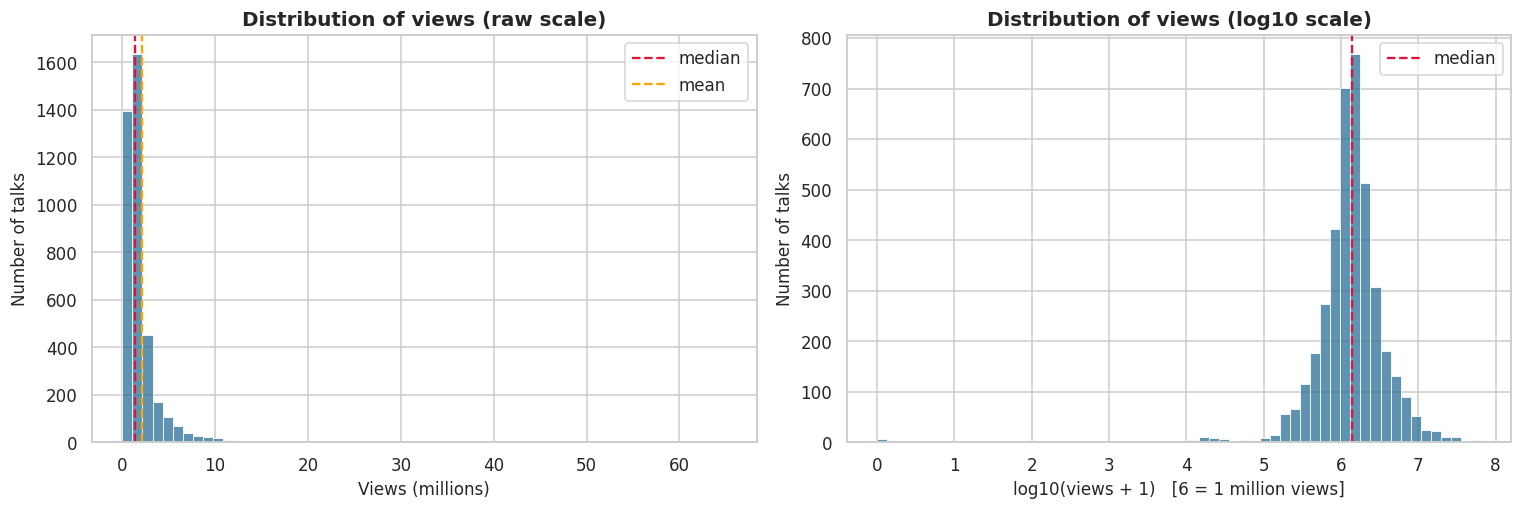

In [15]:
if has_cols("views", "log10_views"):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
    sns.histplot(df["views"] / 1e6, bins=60, ax=ax[0], color="#2a6f97")
    ax[0].axvline(df["views"].median() / 1e6, color="crimson", ls="--", label="median")
    ax[0].axvline(df["views"].mean() / 1e6, color="orange", ls="--", label="mean")
    ax[0].set(title="Distribution of views (raw scale)", xlabel="Views (millions)", ylabel="Number of talks")
    ax[0].legend()
    sns.histplot(df["log10_views"], bins=60, ax=ax[1], color="#2a6f97")
    ax[1].axvline(df["log10_views"].median(), color="crimson", ls="--", label="median")
    ax[1].set(title="Distribution of views (log10 scale)",
              xlabel="log10(views + 1)   [6 = 1 million views]", ylabel="Number of talks")
    ax[1].legend()
    plt.tight_layout()
    plt.show()

In [16]:
if has_cols("views"):
    v = df["views"]
    top10pct = df.nlargest(max(1, int(N * 0.10)), "views")["views"].sum() / v.sum() * 100
    print(f"Views: min {v.min():,.0f} | median {v.median():,.0f} | mean {v.mean():,.0f} | max {v.max():,.0f}")
    print(f"Mean is {v.mean() / v.median():.2f}x the median.")
    print(f"Skewness: {v.skew():.2f} (raw)  ->  {df['log10_views'].skew():.2f} (log10)")
    print(f"The top 10% of talks account for {top10pct:.1f}% of all views.")
    print("\nObservation: a skewness well above 1 on the raw scale means a long tail of very popular talks; the log "
          "scale makes the bulk of the talks visible." if v.skew() > 1 else
          "\nObservation: views are not strongly right-skewed on the raw scale.")

Views: min 0 | median 1,375,508 | mean 2,148,006 | max 65,051,954
Mean is 1.56x the median.
Skewness: 8.19 (raw)  ->  -3.52 (log10)
The top 10% of talks account for 41.3% of all views.

Observation: a skewness well above 1 on the raw scale means a long tail of very popular talks; the log scale makes the bulk of the talks visible.


#### Added: views summary table and outlier check

,views
mean,"2,148,006.00"
median,"1,375,508.00"
min,0.00
max,"65,051,954.00"


High outliers: views above 4,009,672 -> 393 talks (9.8%)
Low outliers (log scale): views below 234,550 -> 151 talks
   Of these low-view talks, 6.6% are not spoken in English.


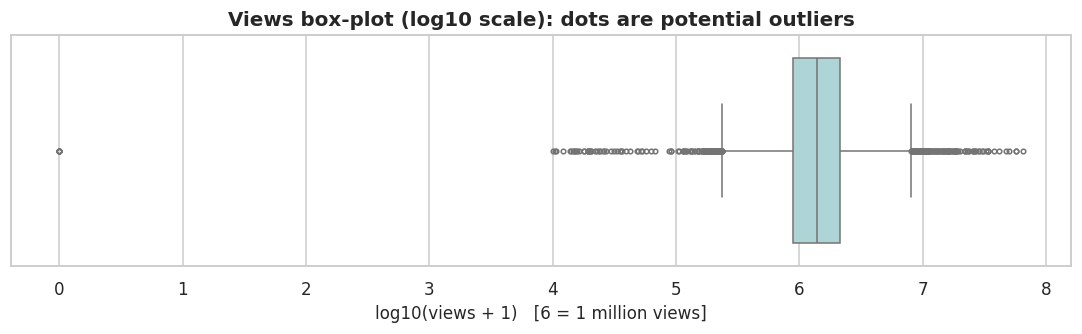

Outliers are kept: they show real differences in popularity, they are not data errors by themselves.


In [17]:
# ---- Views: summary statistics and potential outliers --------------------------------
if has_cols("views"):
    v = df["views"]
    display(v.agg(["mean", "median", "min", "max"]).round(0).to_frame("views"))

    # IQR rule: a value is a potential outlier if it is far outside the middle 50% of the data
    q1, q3 = v.quantile([0.25, 0.75])
    upper_limit = q3 + 1.5 * (q3 - q1)
    high_out = v[v > upper_limit]

    # On the log scale, unusually LOW views can be seen too
    lv = df["log10_views"]
    lq1, lq3 = lv.quantile([0.25, 0.75])
    low_limit = lq1 - 1.5 * (lq3 - lq1)
    low_out = df[lv < low_limit]

    print(f"High outliers: views above {upper_limit:,.0f} -> {len(high_out):,} talks ({pct(len(high_out), N)}%)")
    print(f"Low outliers (log scale): views below {10 ** low_limit - 1:,.0f} -> {len(low_out)} talks")
    if len(low_out) and has_cols("native_lang"):
        print(f"   Of these low-view talks, {pct((low_out['native_lang'] != 'en').sum(), len(low_out))}% are not spoken in English.")

    fig, ax = plt.subplots(figsize=(10, 3.2))
    sns.boxplot(x=df["log10_views"], ax=ax, color="#a8dadc", fliersize=3)
    ax.set(title="Views box-plot (log10 scale): dots are potential outliers",
           xlabel="log10(views + 1)   [6 = 1 million views]")
    plt.tight_layout()
    plt.show()
    print("Outliers are kept: they show real differences in popularity, they are not data errors by themselves.")

### 4.2 Top 10 most-viewed TED Talks

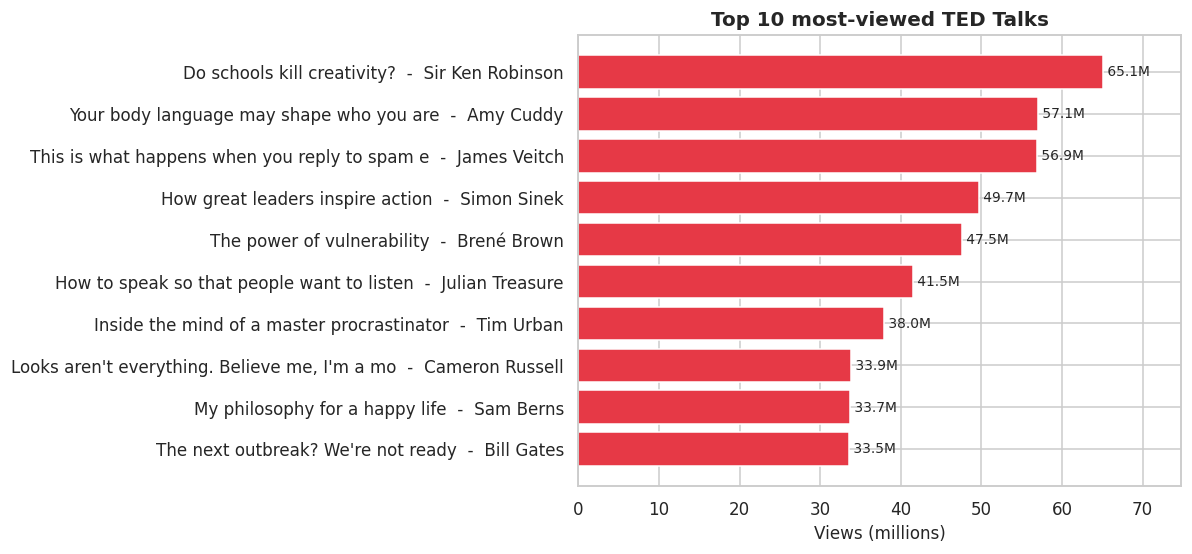

,title,speaker_1,views,published_year
0,Do schools kill creativity?,Sir Ken Robinson,65051954,2006
1,Your body language may shape who you are,Amy Cuddy,57074270,2012
2,This is what happens when you reply to spam email,James Veitch,56932551,2016
3,How great leaders inspire action,Simon Sinek,49730580,2010
4,The power of vulnerability,Brené Brown,47544833,2010
5,How to speak so that people want to listen,Julian Treasure,41504331,2014
6,Inside the mind of a master procrastinator,Tim Urban,37976820,2016
7,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546,2013
8,My philosophy for a happy life,Sam Berns,33691484,2018
9,The next outbreak? We're not ready,Bill Gates,33521780,2015


In [18]:
if has_cols("views", "title"):
    top10 = df.nlargest(10, "views")
    speaker = top10["speaker_1"] if "speaker_1" in df.columns else ""
    labels = top10["title"].str.slice(0, 45) + ("  -  " + speaker if "speaker_1" in df.columns else "")
    fig, ax = plt.subplots(figsize=(11, 5.2))
    ax.barh(labels[::-1], top10["views"][::-1] / 1e6, color="#e63946")
    for y, val in enumerate(top10["views"][::-1] / 1e6):
        ax.text(val, y, f" {val:.1f}M", va="center", fontsize=9)
    ax.set(title="Top 10 most-viewed TED Talks", xlabel="Views (millions)", ylabel="")
    ax.set_xlim(0, top10["views"].max() / 1e6 * 1.15)
    plt.tight_layout()
    plt.show()
    display(top10[[c for c in ["title", "speaker_1", "views", "published_year"] if c in df.columns]].reset_index(drop=True))

### 4.3 Distribution of talk duration

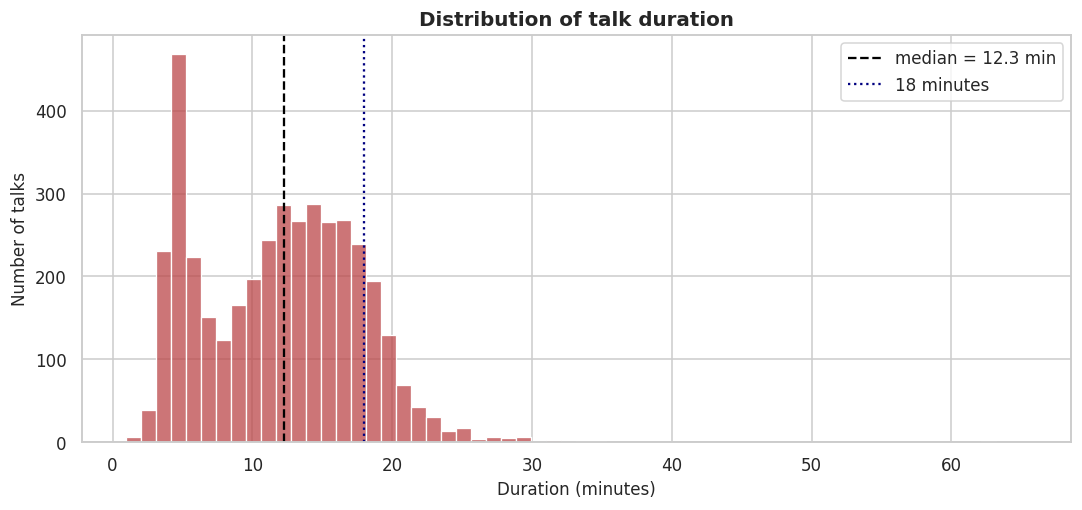

Median 12.3 min | middle 50% between 6.5 and 16.2 min | shortest 1.0 | longest 65.4
85.7% of talks are 18 minutes or shorter.


In [19]:
if has_cols("duration_min"):
    d = df["duration_min"]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    sns.histplot(d, bins=60, ax=ax, color="#bc4749")
    ax.axvline(d.median(), color="black", ls="--", label=f"median = {d.median():.1f} min")
    ax.axvline(18, color="navy", ls=":", label="18 minutes")
    ax.set(title="Distribution of talk duration", xlabel="Duration (minutes)", ylabel="Number of talks")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(f"Median {d.median():.1f} min | middle 50% between {d.quantile(.25):.1f} and {d.quantile(.75):.1f} min | "
          f"shortest {d.min():.1f} | longest {d.max():.1f}")
    print(f"{pct((d <= 18).sum(), N)}% of talks are 18 minutes or shorter.")

#### Added: duration summary and validity check

In [20]:
# ---- Duration: average/median/min/max and missing or invalid values ------------------------------
if has_cols("duration", "duration_min"):
    dur = df["duration"]
    print(f"Duration (minutes): mean {df['duration_min'].mean():.1f} | median {df['duration_min'].median():.1f} | "
          f"min {df['duration_min'].min():.1f} | max {df['duration_min'].max():.1f}")
    checks = {
        "missing duration": int(dur.isna().sum()),
        "non-numeric duration": int(pd.to_numeric(dur, errors="coerce").isna().sum() - dur.isna().sum()),
        "duration <= 0": int((dur <= 0).sum()),
        "duration under 60 seconds": int((dur < 60).sum()),
        "duration over 3 hours": int((dur > 3 * 3600).sum()),
        "duration_min differs from duration / 60": int((abs(df["duration_min"] - dur / 60) > 0.01).sum()),
    }
    display(pd.Series(checks, name="talks").to_frame())
    invalid = checks["missing duration"] + checks["non-numeric duration"] + checks["duration <= 0"]
    print("All durations are valid numbers greater than zero." if invalid == 0 else f"{invalid} invalid durations found.")

Duration (minutes): mean 12.1 | median 12.3 | min 1.0 | max 65.4


,talks
missing duration,0
non-numeric duration,0
duration <= 0,0
duration under 60 seconds,0
duration over 3 hours,0
duration_min differs from duration / 60,0


All durations are valid numbers greater than zero.


### 4.4 Distribution of publication years

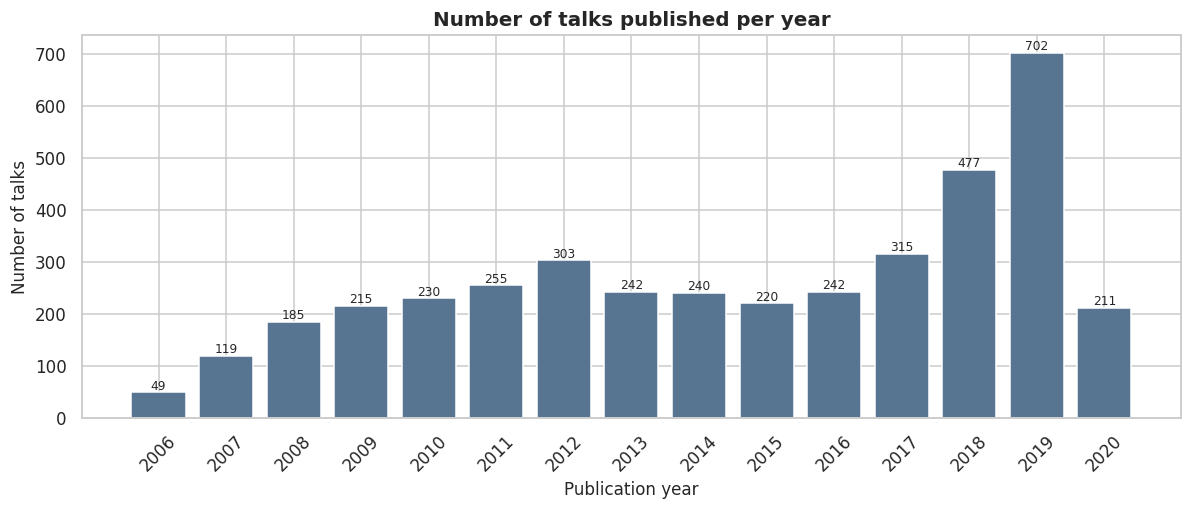

Peak year: 2019 with 702 talks.
Talks published in or after 2017: 42.6%
Last publication date in the data: 2020-04-30 -> 2020 is a partial year (211 talks).


In [21]:
if has_cols("published_year"):
    per_year = df["published_year"].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(11, 4.8))
    bars = ax.bar(per_year.index.astype(str), per_year.values, color="#577590")
    for b, val in zip(bars, per_year.values):
        ax.text(b.get_x() + b.get_width() / 2, val, str(val), ha="center", va="bottom", fontsize=8)
    ax.set(title="Number of talks published per year", xlabel="Publication year", ylabel="Number of talks")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
    last = per_year.index.max()
    print(f"Peak year: {per_year.idxmax()} with {per_year.max()} talks.")
    print(f"Talks published in or after 2017: {pct((df['published_year'] >= 2017).sum(), N)}%")
    if has_cols("published_date"):
        print(f"Last publication date in the data: {df['published_date'].max().date()} "
              f"-> {last} is a partial year ({per_year[last]} talks).")

### 4.5 Distribution of transcript word counts

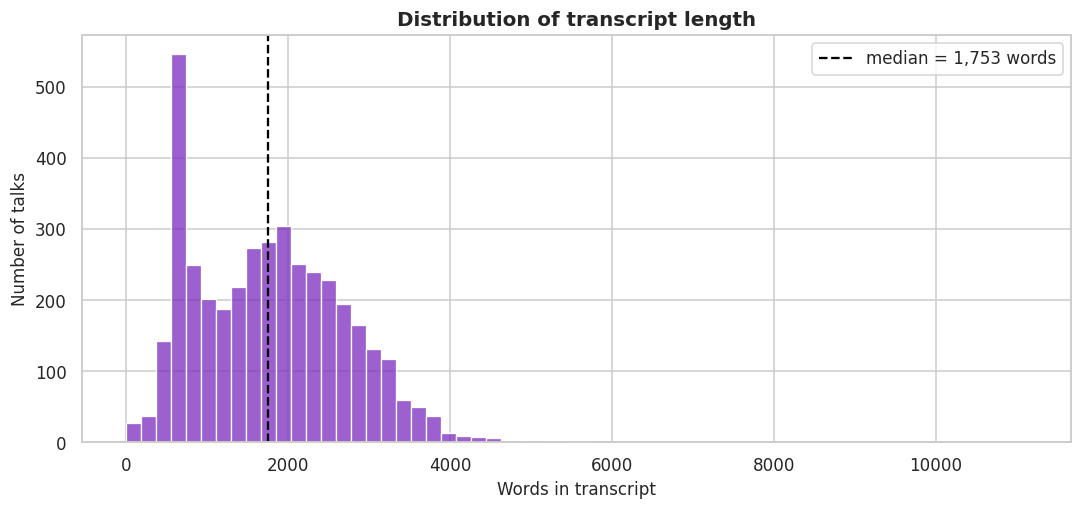

Transcript words: min 2 | median 1,753 | mean 1,797 | max 11,121
Skewness: 1.38


In [22]:
if has_cols("transcript_word_count"):
    w = df["transcript_word_count"]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    sns.histplot(w, bins=60, ax=ax, color="#7b2cbf")
    ax.axvline(w.median(), color="black", ls="--", label=f"median = {w.median():,.0f} words")
    ax.set(title="Distribution of transcript length", xlabel="Words in transcript", ylabel="Number of talks")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(f"Transcript words: min {w.min():,} | median {w.median():,.0f} | mean {w.mean():,.0f} | max {w.max():,}")
    print(f"Skewness: {w.skew():.2f}")

### 4.6 Distribution of comments
Only talks with **real** comment counts are used (talks whose comments were filled with 0 are excluded, see Section 3.3).

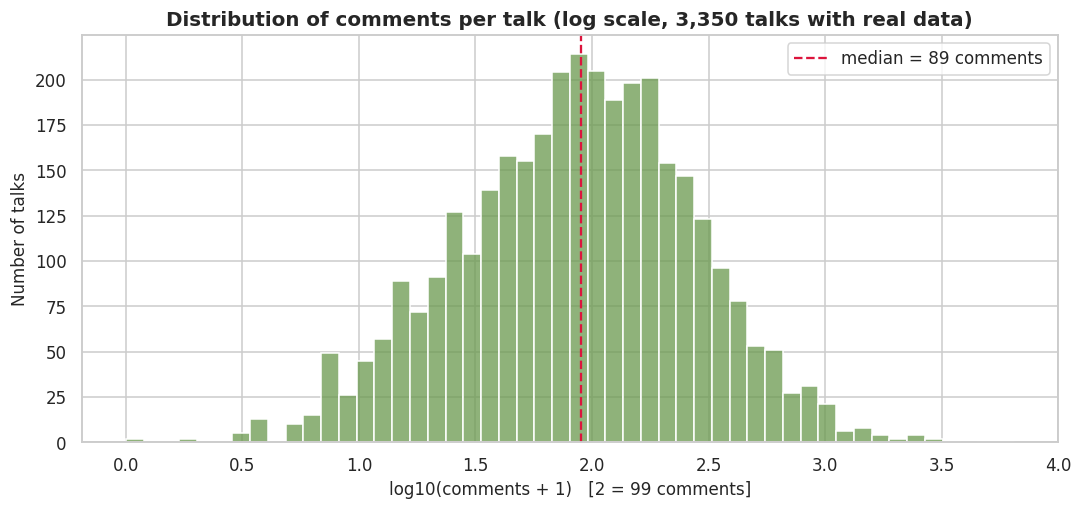

Talks with real comment data: 3,350 (83.6%)  |  excluded (no data): 655
Comments: median 89 | 90th percentile 351 | max 6,449 | skewness 8.87


In [23]:
if has_cols("comments_real"):
    c = df["comments_real"].dropna()
    fig, ax = plt.subplots(figsize=(10, 4.8))
    sns.histplot(np.log10(c + 1), bins=50, ax=ax, color="#6a994e")
    ax.axvline(np.log10(c.median() + 1), color="crimson", ls="--", label=f"median = {c.median():.0f} comments")
    ax.set(title=f"Distribution of comments per talk (log scale, {len(c):,} talks with real data)",
           xlabel="log10(comments + 1)   [2 = 99 comments]", ylabel="Number of talks")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(f"Talks with real comment data: {len(c):,} ({pct(len(c), N)}%)  |  excluded (no data): {N - len(c):,}")
    print(f"Comments: median {c.median():.0f} | 90th percentile {c.quantile(.9):.0f} | max {c.max():,.0f} | skewness {c.skew():.2f}")

#### Added: comment statistics, most-commented talks and outliers
Because 0 was filled in where comments were missing, we compare results **with** and **without** those filled values.

,real values only,including filled zeros (misleading)
mean,162.00,135.50
median,89.00,68.00
min,0.00,0.00
max,"6,449.00","6,449.00"


The mean would be 16.4% too low if the filled zeros were counted.

Top 10 most-commented talks (real comment data only):


,title,speaker_1,comments,views
0,Militant atheism,Richard Dawkins,6449,5788514
1,Do schools kill creativity?,Sir Ken Robinson,4931,65051954
2,Science can answer moral questions,Sam Harris,3424,6331825
3,How do you explain consciousness?,David Chalmers,3006,2910843
4,My stroke of insight,Jill Bolte Taylor,2984,26553231
5,Your body language may shape who you are,Amy Cuddy,2633,57074270
6,Taking imagination seriously,Janet Echelman,2529,2297341
7,On reading the Koran,Lesley Hazleton,2463,2269271
8,The danger of science denial,Michael Specter,2366,2170700
9,The power of vulnerability,Brené Brown,2209,47544833


Outliers: comments above 413 -> 261 talks (7.8% of talks with real comment data)


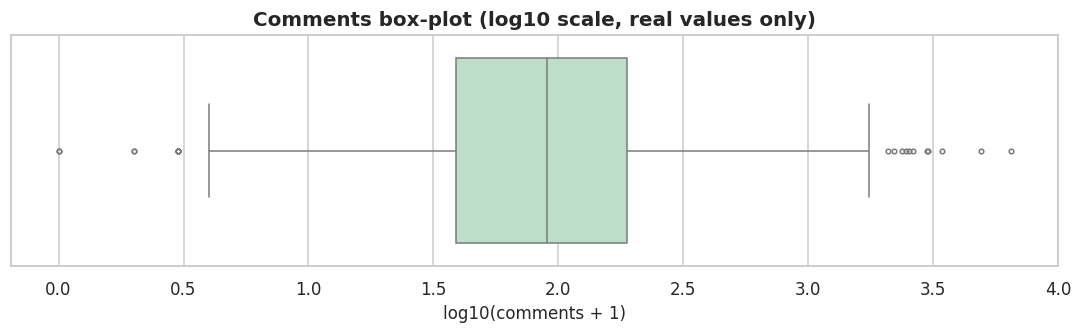

In [24]:
# ---- Comments: statistics, most-commented talks, outliers (real values only) --------------------------------
if has_cols("comments", "comments_real"):
    real = df["comments_real"].dropna()
    comparison = pd.DataFrame({
        "real values only": real.agg(["mean", "median", "min", "max"]),
        "including filled zeros (misleading)": df["comments"].agg(["mean", "median", "min", "max"]),
    }).round(1)
    display(comparison)
    print(f"The mean would be {pct(real.mean() - df['comments'].mean(), real.mean())}% too low if the filled zeros were counted.")

    show_cols = [c for c in ["title", "speaker_1", "comments", "views"] if c in df.columns]
    print("\nTop 10 most-commented talks (real comment data only):")
    display(df.dropna(subset=["comments_real"]).nlargest(10, "comments_real")[show_cols].reset_index(drop=True))

    q1, q3 = real.quantile([0.25, 0.75])
    c_upper = q3 + 1.5 * (q3 - q1)
    print(f"Outliers: comments above {c_upper:,.0f} -> {(real > c_upper).sum():,} talks "
          f"({pct((real > c_upper).sum(), len(real))}% of talks with real comment data)")

    fig, ax = plt.subplots(figsize=(10, 3.2))
    sns.boxplot(x=np.log10(real + 1), ax=ax, color="#b7e4c7", fliersize=3)
    ax.set(title="Comments box-plot (log10 scale, real values only)", xlabel="log10(comments + 1)")
    plt.tight_layout()
    plt.show()

### 4.7 Date analysis
`recorded_date` and `published_date` were converted to real datetime values when the data was loaded (Section 1).
Here we confirm that, find the earliest and latest dates and draw the yearly publication trend.

recorded_date: dtype = datetime64[us] | missing or invalid dates = 0
published_date: dtype = datetime64[us] | missing or invalid dates = 0

Published: earliest 2006-06-27 | latest 2020-04-30
Recorded : earliest 1984-02-02 | latest 2020-04-30
Days between recording and publishing: median 104 | max 8,804 | negative values (recorded after published): 17


published_date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
talks published,49,119,185,215,230,255,303,242,240,220,242,315,477,702,211


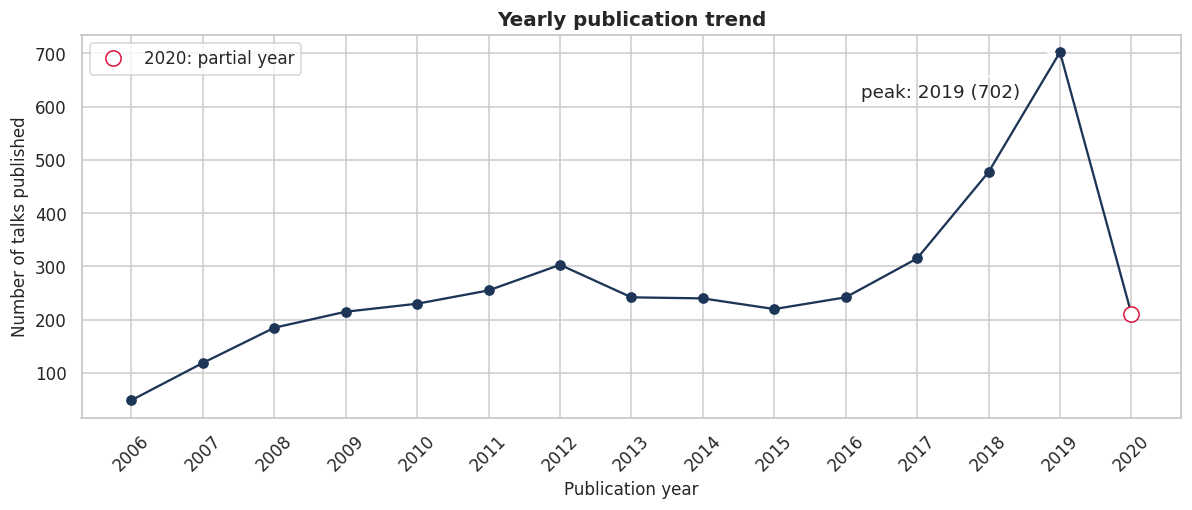

In [25]:
# ---- Dates: type check, range, lag and yearly trend ----------------------------------------------------------
if has_cols("recorded_date", "published_date"):
    for c in ["recorded_date", "published_date"]:
        print(f"{c}: dtype = {df[c].dtype} | missing or invalid dates = {int(df[c].isna().sum())}")

    print(f"\nPublished: earliest {df['published_date'].min().date()} | latest {df['published_date'].max().date()}")
    print(f"Recorded : earliest {df['recorded_date'].min().date()} | latest {df['recorded_date'].max().date()}")

    lag = (df["published_date"] - df["recorded_date"]).dt.days
    print(f"Days between recording and publishing: median {lag.median():,.0f} | max {lag.max():,} | "
          f"negative values (recorded after published): {(lag < 0).sum()}")

    yearly = df.groupby(df["published_date"].dt.year).size()
    display(yearly.rename("talks published").to_frame().T)

    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.plot(yearly.index, yearly.values, marker="o", color="#1d3557")
    last_year = yearly.index.max()
    ax.plot(last_year, yearly.iloc[-1], marker="o", markersize=10, markerfacecolor="white",
            markeredgecolor="crimson", linestyle="", label=f"{last_year}: partial year")
    ax.annotate(f"peak: {yearly.idxmax()} ({yearly.max()})", (yearly.idxmax(), yearly.max()),
                textcoords="offset points", xytext=(-130, -30), arrowprops={"arrowstyle": "->"})
    ax.set(title="Yearly publication trend", xlabel="Publication year", ylabel="Number of talks published")
    ax.set_xticks(yearly.index)
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    plt.tight_layout()
    plt.show()

## 5. Topic analysis
Each talk has several topic tags stored in one text cell, separated by `|`
(example format: `science | technology | climate change`).  
Steps: **split** the text on `|` -> **strip** spaces -> **lower-case** -> ignore **empty** pieces -> **count**.
Talks with missing or empty topics simply get an empty list, so nothing crashes.

**Status: COMPLETED**

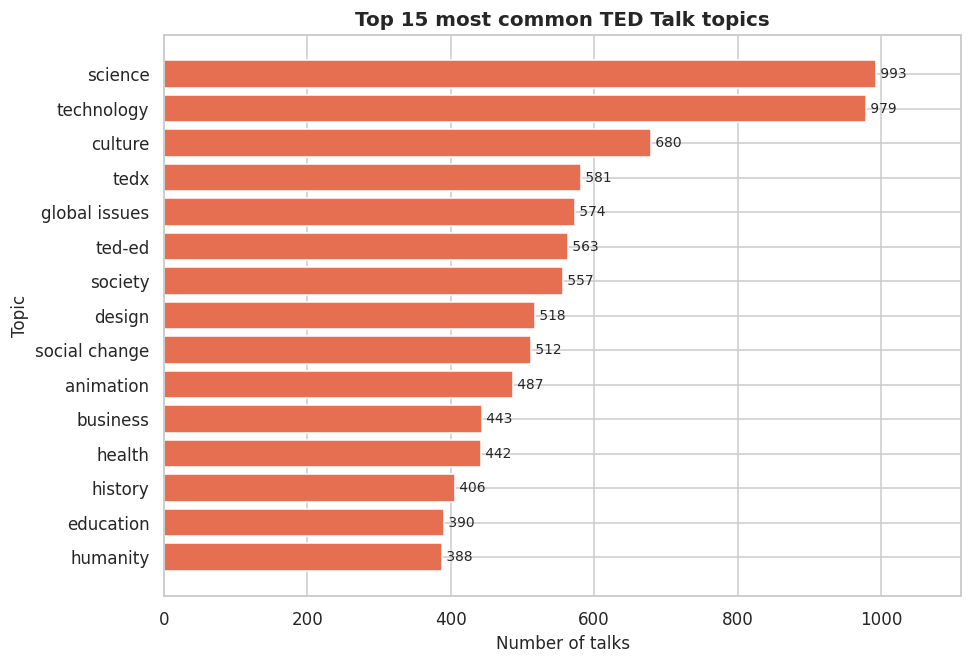

In [26]:
if has_cols("topics"):
    # split safely: NaN -> "", then split on "|", strip spaces, drop empty pieces
    topic_lists = (df["topics"].fillna("").astype(str).str.split("|")
                   .apply(lambda parts: [t.strip().lower() for t in parts if t.strip()]))

    talks_without_topics = int((topic_lists.str.len() == 0).sum())
    topic_counts = pd.Series([t for lst in topic_lists for t in lst]).value_counts()
    top15 = topic_counts.head(15)

    fig, ax = plt.subplots(figsize=(9, 6.2))
    ax.barh(top15.index[::-1], top15.values[::-1], color="#e76f51")
    for y, val in enumerate(top15.values[::-1]):
        ax.text(val, y, f" {val:,}", va="center", fontsize=9)
    ax.set(title="Top 15 most common TED Talk topics", xlabel="Number of talks", ylabel="Topic")
    ax.set_xlim(0, top15.max() * 1.12)
    plt.tight_layout()
    plt.show()

In [27]:
if has_cols("topics"):
    print(f"Talks with missing/empty topics: {talks_without_topics}")
    print(f"Distinct topics: {topic_counts.size:,}")
    print(f"Average topics per talk: {topic_lists.str.len().mean():.1f} (min {topic_lists.str.len().min()}, max {topic_lists.str.len().max()})")
    print(f"Topics used by only 1 talk: {(topic_counts == 1).sum():,} | by 5 talks or fewer: {(topic_counts <= 5).sum():,}")
    print(f"Most common topic: '{top15.index[0]}' in {top15.iloc[0]:,} talks ({pct(top15.iloc[0], N)}% of talks)")
    fmt_tags = [t for t in top15.index if t.startswith("ted")]
    if fmt_tags:
        print(f"\nNote: {fmt_tags} in the top 15 describe the FORMAT/brand of the talk, not its subject.")

Talks with missing/empty topics: 0
Distinct topics: 457
Average topics per talk: 7.9 (min 1, max 33)
Topics used by only 1 talk: 5 | by 5 talks or fewer: 33
Most common topic: 'science' in 993 talks (24.8% of talks)

Note: ['tedx', 'ted-ed'] in the top 15 describe the FORMAT/brand of the talk, not its subject.


### 5.1 Number of topics per talk

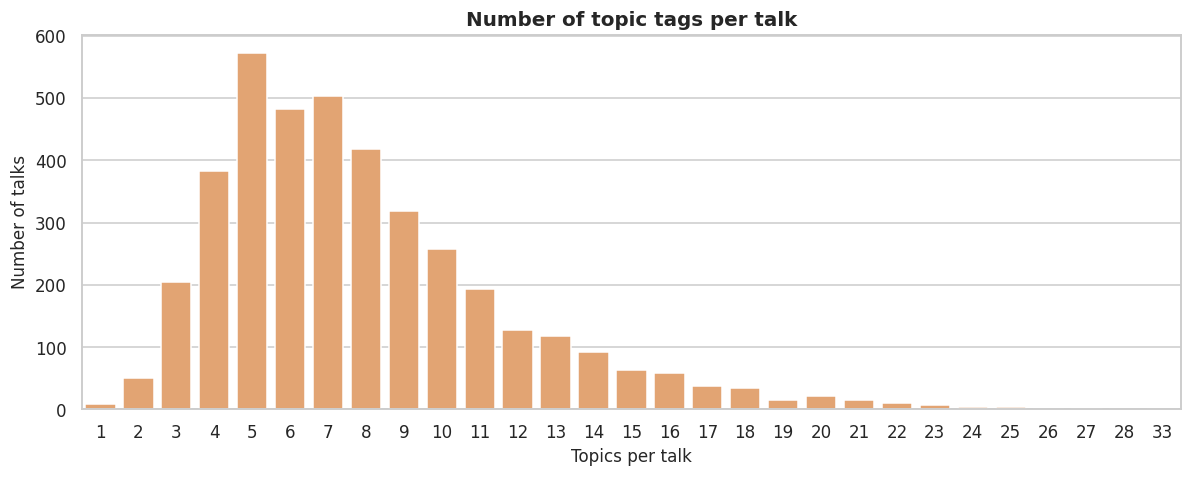

Topics per talk: mean 7.9 | median 7 | most common 5 | min 1 | max 33
Talks with only 1-2 topics: 1.5%
Existing num_topics column matches the counted topics: True


In [28]:
if has_cols("topics"):
    per_talk = topic_lists.str.len()            # topic_lists was created above (split on "|")
    fig, ax = plt.subplots(figsize=(11, 4.5))
    sns.countplot(x=per_talk, ax=ax, color="#f4a261")
    ax.set(title="Number of topic tags per talk", xlabel="Topics per talk", ylabel="Number of talks")
    plt.tight_layout()
    plt.show()
    print(f"Topics per talk: mean {per_talk.mean():.1f} | median {per_talk.median():.0f} | most common {per_talk.mode().iloc[0]} "
          f"| min {per_talk.min()} | max {per_talk.max()}")
    print(f"Talks with only 1-2 topics: {pct((per_talk <= 2).sum(), N)}%")
    if "num_topics" in df.columns:
        print("Existing num_topics column matches the counted topics:", bool((df["num_topics"] == per_talk).all()))

## 6. Speaker analysis
We use `speaker_1` (main speaker) and `all_speakers` (every speaker of the talk, separated by `|`).
Names are used exactly as written in the data.

**Status: COMPLETED**

In [29]:
# ---- Unique speakers -------------------------------------------------------------------------------------
if has_cols("speaker_1", "all_speakers"):
    main_speakers = df["speaker_1"].astype(str).str.strip()
    all_lists = (df["all_speakers"].fillna("").astype(str).str.split("|")
                 .apply(lambda parts: [s.strip() for s in parts if s.strip()]))
    all_individuals = pd.Series([s for names in all_lists for s in names])

    multi_speaker_talks = int((all_lists.str.len() > 1).sum())
    only_cospeakers = set(all_individuals) - set(main_speakers)
    print(f"Unique main speakers (speaker_1):          {main_speakers.nunique():,}")
    print(f"Unique individual speakers (all_speakers):  {all_individuals.nunique():,}")
    print(f"Talks with more than one speaker: {multi_speaker_talks} ({pct(multi_speaker_talks, N)}%)")
    print(f"People who appear only as co-speakers (never as speaker_1): {len(only_cospeakers)}")
    if "num_speakers" in df.columns:
        print("Existing num_speakers column matches all_speakers:", bool((df["num_speakers"] == all_lists.str.len()).all()))

Unique main speakers (speaker_1):          3,274
Unique individual speakers (all_speakers):  3,353
Talks with more than one speaker: 114 (2.8%)
People who appear only as co-speakers (never as speaker_1): 79
Existing num_speakers column matches all_speakers: True


Speakers with 2 or more talks: 448 (13.4% of all speakers)
Speakers with exactly 1 talk:  2,905
Most talks by one speaker: 34


,talks,total_views,median_views
speaker,,,
Alex Gendler,34,117619583,"1,663,325.00"
Chris Anderson,27,66929487,"1,585,801.00"
Iseult Gillespie,20,17632387,"558,986.00"
Emma Bryce,12,24554552,"1,728,812.50"
Daniel Finkel,11,15897420,"1,444,428.00"
Hans Rosling,10,39871561,"3,032,717.50"
Alex Rosenthal,10,3343962,"260,583.00"
Greg Gage,9,18359012,"843,602.00"
Juan Enriquez,9,18311605,"1,990,039.00"


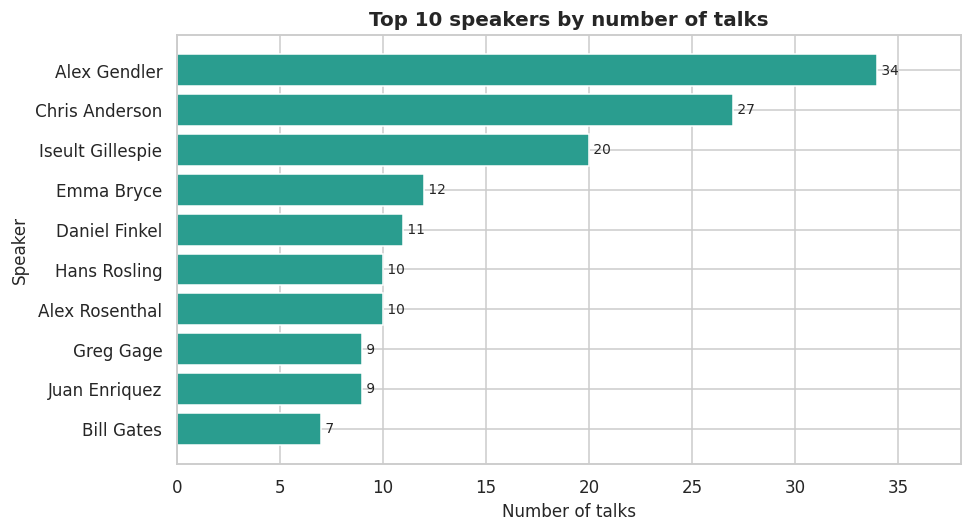

In [30]:
# ---- Speakers with multiple talks + top 10 chart -----------------------------------------------------------------
if has_cols("speaker_1", "all_speakers", "views"):
    talks_per_speaker = all_individuals.value_counts()
    repeat_speakers = talks_per_speaker[talks_per_speaker >= 2]
    print(f"Speakers with 2 or more talks: {len(repeat_speakers):,} "
          f"({pct(len(repeat_speakers), len(talks_per_speaker))}% of all speakers)")
    print(f"Speakers with exactly 1 talk:  {(talks_per_speaker == 1).sum():,}")
    print(f"Most talks by one speaker: {talks_per_speaker.max()}")

    # one row per (talk, speaker) so co-speakers are counted too
    exploded = df.assign(speaker=all_lists).explode("speaker")
    speaker_stats = exploded.groupby("speaker").agg(talks=("speaker", "size"), total_views=("views", "sum"),
                                                    median_views=("views", "median"))
    top10_speakers = speaker_stats.sort_values(["talks", "total_views"], ascending=False).head(10)
    display(top10_speakers)

    plot_data = top10_speakers["talks"][::-1]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(plot_data.index, plot_data.values, color="#2a9d8f")
    for y, val in enumerate(plot_data.values):
        ax.text(val, y, f" {val}", va="center", fontsize=9)
    ax.set(title="Top 10 speakers by number of talks", xlabel="Number of talks", ylabel="Speaker")
    ax.set_xlim(0, plot_data.max() * 1.12)
    plt.tight_layout()
    plt.show()

## 7. Language analysis
`native_lang` = language spoken in the talk. `available_lang` = subtitle languages (separated by `|`).
We also check for missing or inconsistent values (empty text, odd codes, upper-case/space variants).

**Status: COMPLETED**

Missing or blank native_lang: 0
Values that do not look like a language code: 0
Values with extra spaces or capital letters: 0
Distinct spoken languages: 12


,talks,percent
native_lang,,
en,3957,98.80
es,27,0.70
fr,9,0.20
ja,3,0.10
hi,2,0.00
de,1,0.00
pt,1,0.00
ko,1,0.00
zh-cn,1,0.00


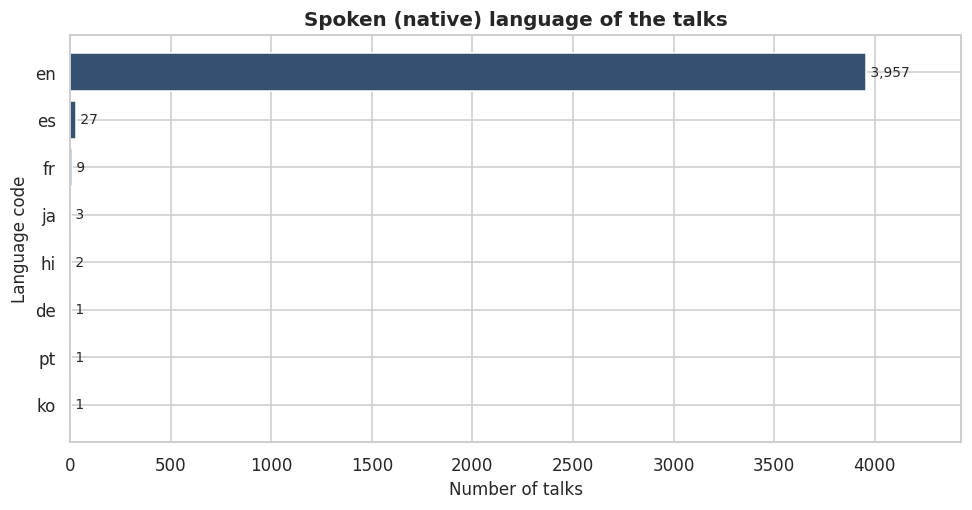

In [31]:
# ---- Native (spoken) language ----------------------------------------------------------------------------------
if has_cols("native_lang"):
    nl = df["native_lang"].astype(str).str.strip()
    native_counts = nl.value_counts()
    odd_codes = nl[~nl.str.match(r"^[a-z]{2,3}(-[a-z]{2,4})?$")]          # expected pattern like 'en' or 'pt-br'
    print(f"Missing or blank native_lang: {int(is_blank(df['native_lang']).sum())}")
    print(f"Values that do not look like a language code: {len(odd_codes)}")
    print(f"Values with extra spaces or capital letters: {int((df['native_lang'].astype(str) != nl.str.lower()).sum())}")
    print(f"Distinct spoken languages: {native_counts.size}")
    display(native_counts.to_frame("talks").assign(percent=lambda t: (t["talks"] / N * 100).round(1)))

    top_native = native_counts.head(8)[::-1]
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.barh(top_native.index, top_native.values, color="#355070")
    for y, val in enumerate(top_native.values):
        ax.text(val, y, f" {val:,}", va="center", fontsize=9)
    ax.set(title="Spoken (native) language of the talks", xlabel="Number of talks", ylabel="Language code")
    ax.set_xlim(0, top_native.max() * 1.12)
    plt.tight_layout()
    plt.show()

Distinct subtitle languages: 114
Languages available per talk: mean 25.3 | median 25 | min 1 | max 73
Talks with no available language listed: 0
Talks whose list repeats a language: 0
Talks whose spoken language is NOT in their available list: 0


Existing num_languages column matches the lists: True


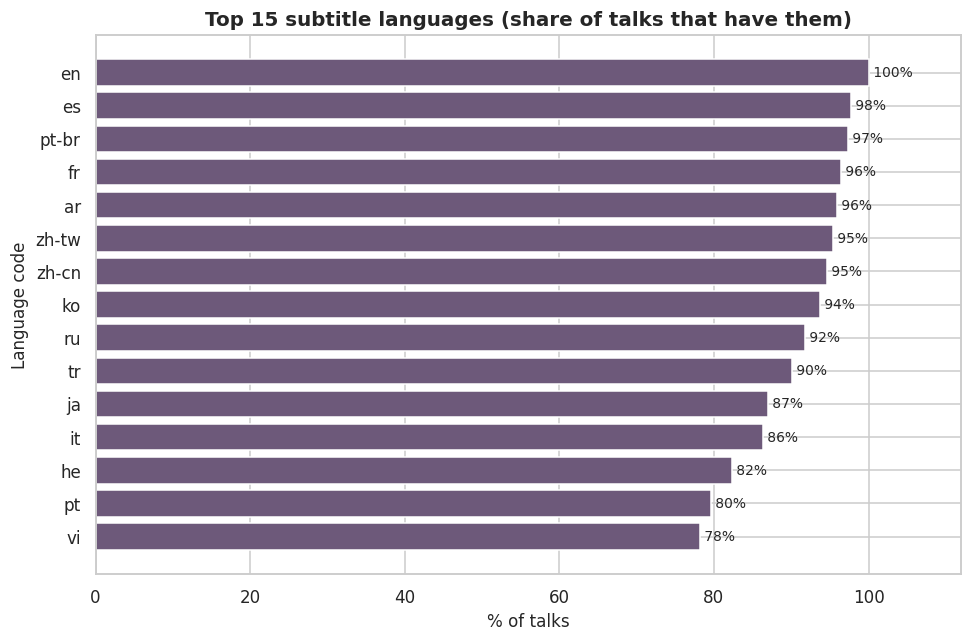

In [32]:
# ---- Language availability (subtitles) ---------------------------------------------------------------------------------
if has_cols("available_lang"):
    avail_lists = (df["available_lang"].fillna("").astype(str).str.split("|")
                   .apply(lambda parts: [s.strip() for s in parts if s.strip()]))
    avail_counts = pd.Series([s for names in avail_lists for s in names]).value_counts()
    per_talk_langs = avail_lists.str.len()

    print(f"Distinct subtitle languages: {avail_counts.size}")
    print(f"Languages available per talk: mean {per_talk_langs.mean():.1f} | median {per_talk_langs.median():.0f} | "
          f"min {per_talk_langs.min()} | max {per_talk_langs.max()}")
    print(f"Talks with no available language listed: {int((per_talk_langs == 0).sum())}")
    print(f"Talks whose list repeats a language: {int(avail_lists.apply(lambda l: len(l) != len(set(l))).sum())}")
    if has_cols("native_lang"):
        native_missing = [nat not in langs for nat, langs in zip(nl, avail_lists)]
        print(f"Talks whose spoken language is NOT in their available list: {sum(native_missing)}")
    if "num_languages" in df.columns:
        print("Existing num_languages column matches the lists:", bool((df["num_languages"] == per_talk_langs).all()))

    top_avail = (avail_counts.head(15) / N * 100)[::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top_avail.index, top_avail.values, color="#6d597a")
    for y, val in enumerate(top_avail.values):
        ax.text(val, y, f" {val:.0f}%", va="center", fontsize=9)
    ax.set(title="Top 15 subtitle languages (share of talks that have them)", xlabel="% of talks", ylabel="Language code")
    ax.set_xlim(0, 112)
    plt.tight_layout()
    plt.show()

## 8. Event and occupation analysis
`event` is the TED event where the talk was given. `occupations` lists the speaker occupations, separated by `|`
(the placeholder `Unknown` is counted separately and left out of the chart).

**Status: COMPLETED**

Distinct events: 459 | missing or blank: 0
Events with only 1 talk: 203
Event names that differ only by capital letters or spaces: 0
Top 5 events together hold 23.0% of all talks.


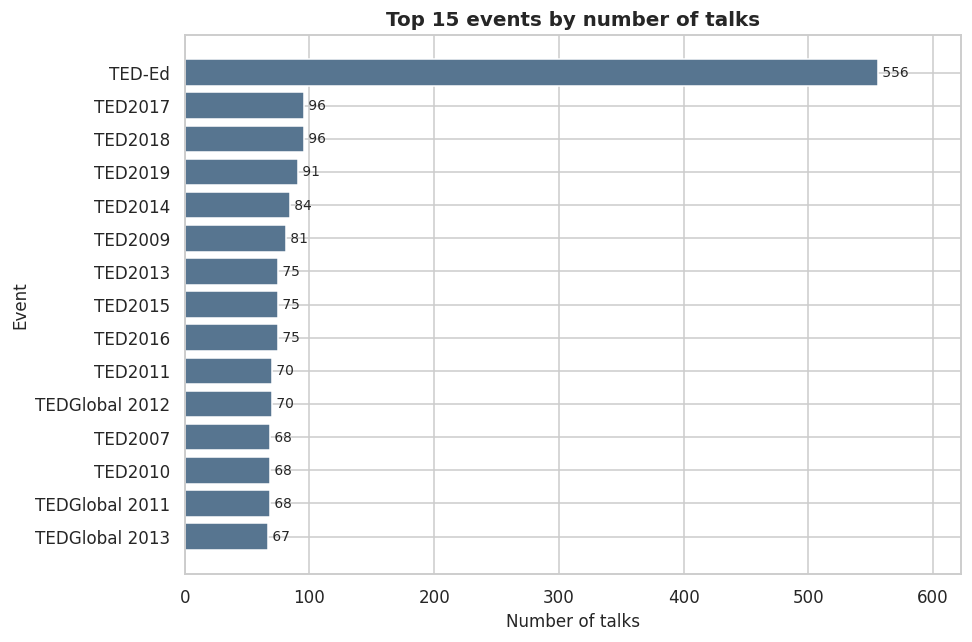

In [33]:
# ---- Events ----------------------------------------------------------------------------------------------------------------
if has_cols("event"):
    ev = df["event"].astype(str).str.strip()
    event_counts = ev.value_counts()
    same_name_variants = ev.nunique() - ev.str.lower().str.replace(r"\s+", "", regex=True).nunique()
    print(f"Distinct events: {event_counts.size:,} | missing or blank: {int(is_blank(df['event']).sum())}")
    print(f"Events with only 1 talk: {(event_counts == 1).sum():,}")
    print(f"Event names that differ only by capital letters or spaces: {same_name_variants}")
    print(f"Top 5 events together hold {pct(event_counts.head(5).sum(), N)}% of all talks.")

    top_events = event_counts.head(15)[::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top_events.index, top_events.values, color="#577590")
    for y, val in enumerate(top_events.values):
        ax.text(val, y, f" {val:,}", va="center", fontsize=9)
    ax.set(title="Top 15 events by number of talks", xlabel="Number of talks", ylabel="Event")
    ax.set_xlim(0, top_events.max() * 1.12)
    plt.tight_layout()
    plt.show()

Talks with unknown occupation: 522 (13.0%)
Distinct occupations (Unknown excluded): 1,796
Occupations that appear only once: 1,310
Talks listing more than one occupation: 795


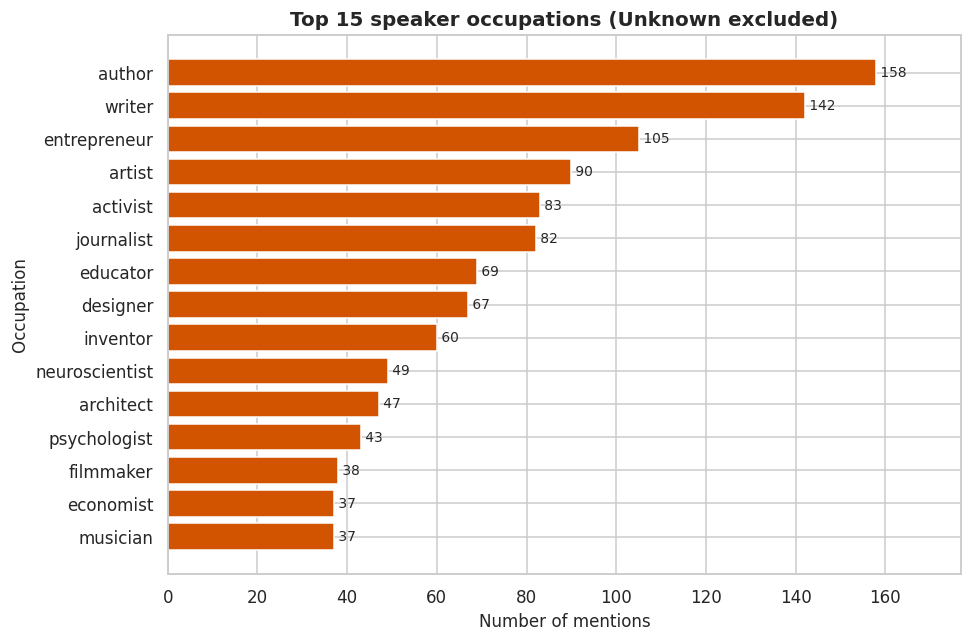

In [34]:
# ---- Occupations ------------------------------------------------------------------------------------------------------------------
if has_cols("occupations"):
    occ_lists = (df["occupations"].fillna("").astype(str).str.split("|")
                 .apply(lambda parts: [s.strip().lower() for s in parts if s.strip()]))
    unknown_talks = int(occ_lists.apply(lambda l: l == ["unknown"]).sum())
    all_occ = pd.Series([o for names in occ_lists for o in names if o != "unknown"])
    occ_counts = all_occ.value_counts()

    print(f"Talks with unknown occupation: {unknown_talks} ({pct(unknown_talks, N)}%)")
    print(f"Distinct occupations (Unknown excluded): {occ_counts.size:,}")
    print(f"Occupations that appear only once: {(occ_counts == 1).sum():,}")
    print(f"Talks listing more than one occupation: {int((occ_lists.str.len() > 1).sum())}")

    top_occ = occ_counts.head(15)[::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top_occ.index, top_occ.values, color="#d35400")
    for y, val in enumerate(top_occ.values):
        ax.text(val, y, f" {val:,}", va="center", fontsize=9)
    ax.set(title="Top 15 speaker occupations (Unknown excluded)", xlabel="Number of mentions", ylabel="Occupation")
    ax.set_xlim(0, top_occ.max() * 1.12)
    plt.tight_layout()
    plt.show()

## 9. Related talks analysis
`related_talks` holds the **titles** and `related_talk_ids` the **IDs** of talks that TED lists as related (separated by `|`).
We count them per talk and check whether the listed IDs really exist in this dataset.

**Status: COMPLETED**

Related IDs per talk: min 1 | median 6 | max 6
Talks with no related talks listed: 0
Talks where the number of related titles differs from the number of IDs: 8

Total related-talk references: 23,915
References that exist in this dataset: 23,793 (99.5%)
References to IDs NOT in this dataset: 122 (56 distinct IDs)
Talks with at least one usable related talk: 4,004 (100.0%)
Talks where ALL listed related talks exist here: 3,890
Talks that list themselves as related: 4
Talks never listed as related by any other talk: 239


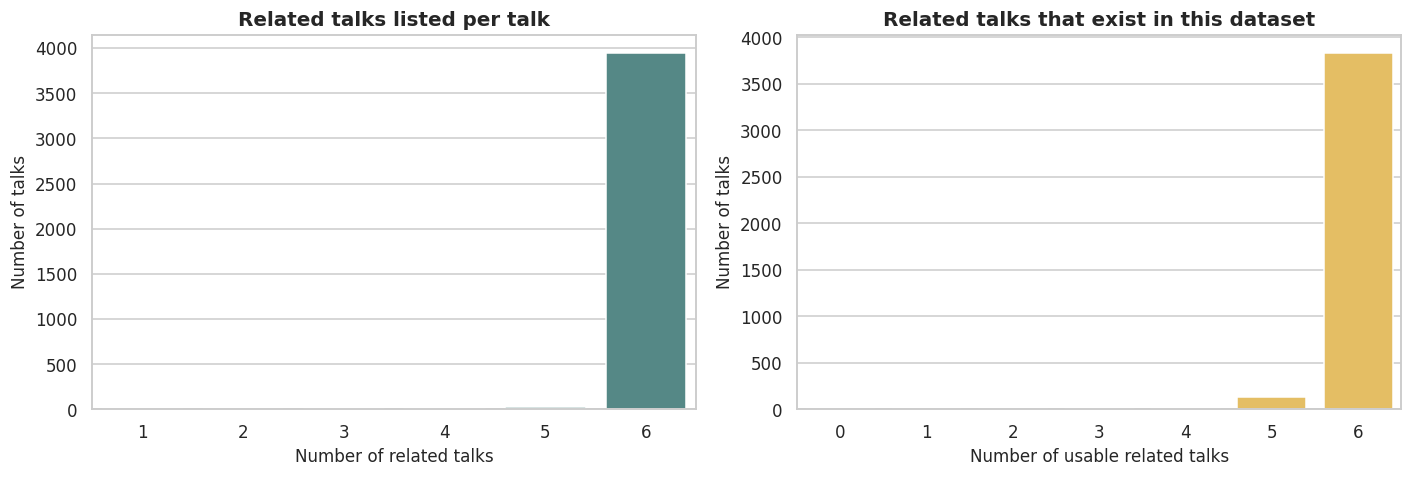

In [35]:
if has_cols("related_talks", "related_talk_ids", "talk_id"):
    def parse_ids(text):
        """'12 | 345 | 6'  ->  [12, 345, 6]   (empty or missing text -> [])"""
        return [int(x) for x in str(text).replace("|", " ").split() if x.isdigit()] if pd.notna(text) else []

    rel_ids = df["related_talk_ids"].map(parse_ids)
    rel_titles = df["related_talks"].fillna("").astype(str).map(lambda s: [t for t in s.split(" | ") if t.strip()])
    n_ids = rel_ids.str.len()
    print(f"Related IDs per talk: min {n_ids.min()} | median {n_ids.median():.0f} | max {n_ids.max()}")
    print(f"Talks with no related talks listed: {int((n_ids == 0).sum())}")
    print(f"Talks where the number of related titles differs from the number of IDs: {int((rel_titles.str.len() != n_ids).sum())}")

    # Do the listed IDs exist in the dataset?
    known_ids = set(df["talk_id"])
    found_per_talk = rel_ids.apply(lambda ids: sum(i in known_ids for i in ids))
    total_refs, found_refs = int(n_ids.sum()), int(found_per_talk.sum())
    missing_unique = {i for ids in rel_ids for i in ids if i not in known_ids}
    print(f"\nTotal related-talk references: {total_refs:,}")
    print(f"References that exist in this dataset: {found_refs:,} ({pct(found_refs, total_refs)}%)")
    print(f"References to IDs NOT in this dataset: {total_refs - found_refs:,} ({len(missing_unique):,} distinct IDs)")
    print(f"Talks with at least one usable related talk: {int((found_per_talk > 0).sum()):,} ({pct((found_per_talk > 0).sum(), N)}%)")
    print(f"Talks where ALL listed related talks exist here: {int((found_per_talk == n_ids).sum()):,}")
    print(f"Talks that list themselves as related: {int(sum(t in ids for t, ids in zip(df['talk_id'], rel_ids)))}")

    # How often is each talk listed as 'related' by other talks?
    referenced = pd.Series([i for ids in rel_ids for i in ids if i in known_ids]).value_counts()
    print(f"Talks never listed as related by any other talk: {N - referenced.size:,}")

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.countplot(x=n_ids, ax=ax[0], color="#4d908e")
    ax[0].set(title="Related talks listed per talk", xlabel="Number of related talks", ylabel="Number of talks")
    sns.countplot(x=found_per_talk, ax=ax[1], color="#f9c74f")
    ax[1].set(title="Related talks that exist in this dataset", xlabel="Number of usable related talks", ylabel="Number of talks")
    plt.tight_layout()
    plt.show()

### How related talks can help evaluate recommendations
TED lists related talks for each talk. Later, when a recommender suggests talks similar to talk *A*, we can check how many of TED's
related talks for *A* appear in our top-N list (for example hit rate or recall at N). Only related IDs that exist in this dataset can be used.
Two cautions: TED's lists are one editorial opinion (not user feedback), and a good recommendation that TED did not list is not necessarily wrong.
So related talks are a **helpful reference, not perfect ground truth**.

## 10. Bivariate analysis
Bivariate analysis studies **two variables together**. We use *Spearman rank correlation* because views and comments are
strongly skewed (Spearman is not distorted by a few extreme values). It ranges from -1 to +1.

> **Correlation does not establish causation.** If two variables move together, it does not prove that one causes the other.
> A third factor may drive both, or the direction of cause may be the opposite one.

**Status: COMPLETED**

### 10.1 Views versus comments (real comment data only)

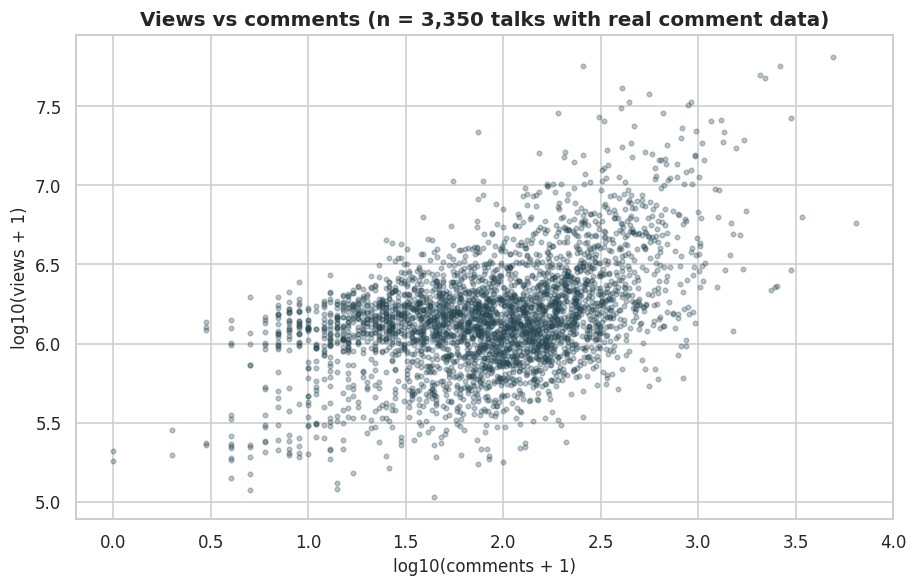

Spearman correlation: 0.38


In [36]:
if has_cols("comments_real", "log10_views"):
    sub = df.dropna(subset=["comments_real"])
    rho = sub["views"].corr(sub["comments_real"], method="spearman")
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    ax.scatter(sub["log10_comments_real"], sub["log10_views"], s=9, alpha=0.3, color="#264653")
    ax.set(title=f"Views vs comments (n = {len(sub):,} talks with real comment data)",
           xlabel="log10(comments + 1)", ylabel="log10(views + 1)")
    plt.tight_layout()
    plt.show()
    print(f"Spearman correlation: {rho:.2f}")

### 10.2 Duration versus views
The red line shows the **median** views for 10 equal-size groups of talk length (a simple trend).

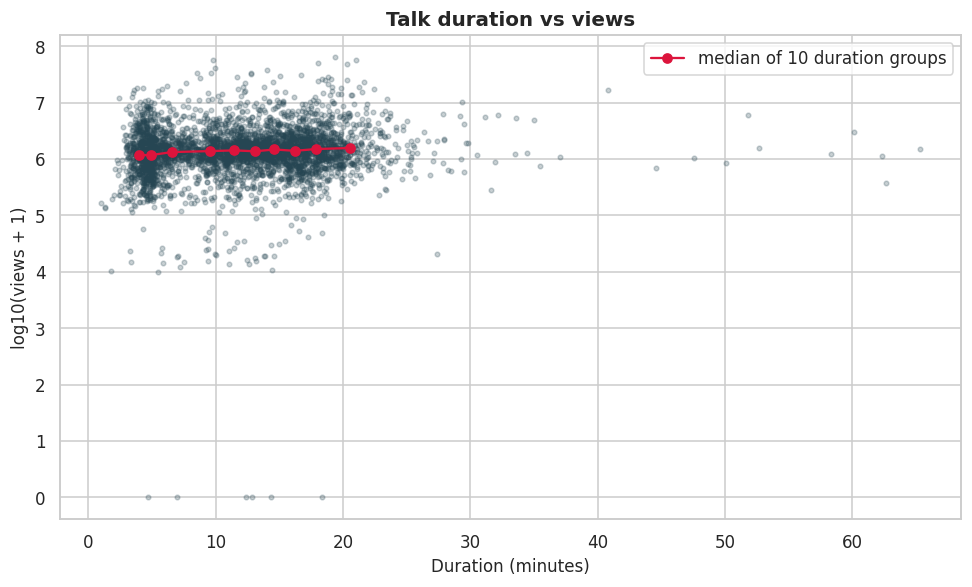

Spearman correlation: 0.11
Duration group with the highest median views: around 20.5 min (median views about 1,567,907).


In [37]:
if has_cols("duration_min", "log10_views"):
    trend = binned_median(df["duration_min"], df["log10_views"])
    rho = df["duration_min"].corr(df["views"], method="spearman")
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.scatter(df["duration_min"], df["log10_views"], s=9, alpha=0.25, color="#264653")
    ax.plot(trend["x"], trend["y"], color="crimson", marker="o", label="median of 10 duration groups")
    ax.set(title="Talk duration vs views", xlabel="Duration (minutes)", ylabel="log10(views + 1)")
    ax.legend()
    plt.tight_layout()
    plt.show()
    best = int(trend["y"].values.argmax())   # position of the highest median
    print(f"Spearman correlation: {rho:.2f}")
    print(f"Duration group with the highest median views: around {trend['x'].iloc[best]:.1f} min "
          f"(median views about {10 ** trend['y'].iloc[best] - 1:,.0f}).")

### 10.3 Publication year versus views

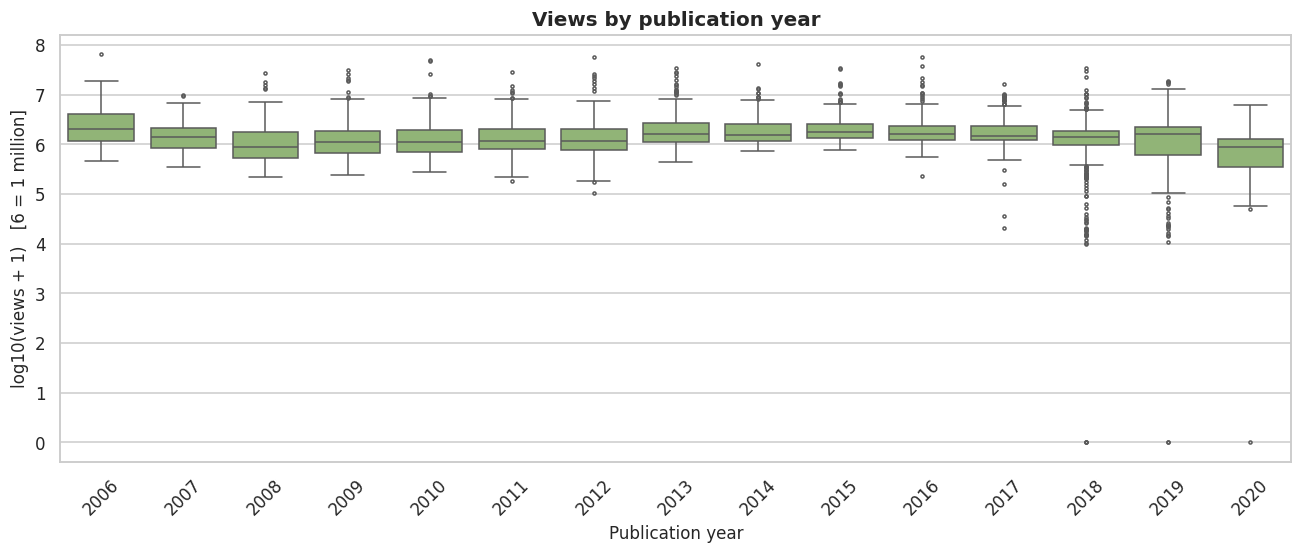

published_year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
talks,49.00,119.00,185.00,215.00,230.00,255.00,303.00,242.00,240.00,220.00,242.00,315.00,477.00,702.00,211.00
median_views,"2,060,305.00","1,377,588.00","893,977.00","1,083,790.00","1,097,755.00","1,170,370.00","1,176,143.00","1,597,482.00","1,536,921.00","1,736,281.00","1,626,986.00","1,473,383.00","1,383,101.00","1,583,304.00","880,753.00"


Spearman correlation between publication year and views: -0.01
Highest median views: 2006 | lowest: 2020
Note: the last year is incomplete, so its numbers are less reliable.


In [38]:
if has_cols("published_year", "log10_views"):
    fig, ax = plt.subplots(figsize=(12, 5.2))
    sns.boxplot(data=df, x="published_year", y="log10_views", ax=ax, color="#90be6d", fliersize=2)
    ax.set(title="Views by publication year", xlabel="Publication year", ylabel="log10(views + 1)   [6 = 1 million]")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
    by_year = df.groupby("published_year")["views"].agg(talks="count", median_views="median").round(0)
    display(by_year.T)
    rho = df["published_year"].corr(df["views"], method="spearman")
    print(f"Spearman correlation between publication year and views: {rho:.2f}")
    print(f"Highest median views: {by_year['median_views'].idxmax()} | lowest: {by_year['median_views'].idxmin()}")
    print("Note: the last year is incomplete, so its numbers are less reliable.")

### 10.4 Correlation overview of the numeric features

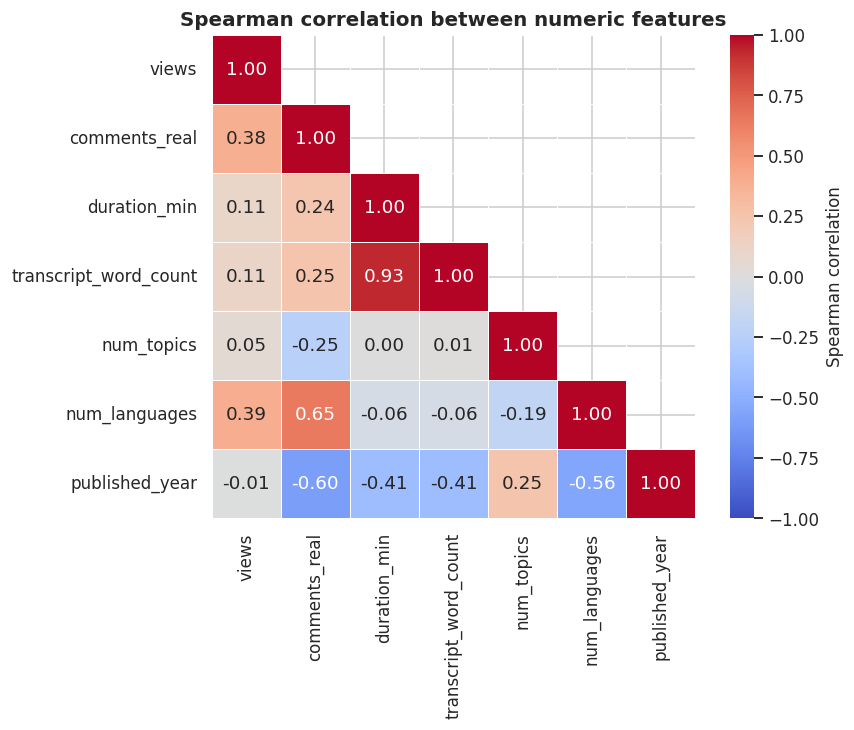

Correlation with views (strongest first):
num_languages            0.39
comments_real            0.38
transcript_word_count    0.11
duration_min             0.11
num_topics               0.05
published_year          -0.01


In [39]:
heat_cols = [c for c in ["views", "comments_real", "duration_min", "transcript_word_count",
                         "num_topics", "num_languages", "published_year"] if c in df.columns]
if len(heat_cols) >= 3:
    corr = df[heat_cols].corr(method="spearman")
    fig, ax = plt.subplots(figsize=(8.5, 6.8))
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
                cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
                cbar_kws={"label": "Spearman correlation"}, ax=ax)
    ax.set_title("Spearman correlation between numeric features")
    plt.tight_layout()
    plt.show()
    if "views" in corr:
        print("Correlation with views (strongest first):")
        print(corr["views"].drop("views").sort_values(key=abs, ascending=False).round(2).to_string())

**Reading the heat-map:** values near +1 mean two features rise together, near -1 mean one rises while the other falls,
near 0 mean no consistent rank relationship. Remember: **association is not causation**.
Two features that are strongly correlated with each other (for example duration and transcript length) carry overlapping information.

## 11. Text analysis
A **content-based** recommender compares what talks are *about*. The raw material is text:
- **Title** - short and information-rich, 
- **Description** - a concise summary written by TED, 
- **Topics** - curated tags, 
- **Transcript** - the full spoken content (the richest, but also the longest and noisiest source).

We first inspect these fields, then build a `combined_text` column **in memory** (no file is written, no model is trained).

**Status: COMPLETED**

### 11.1 Inspect the text fields

In [40]:
text_fields = [c for c in ["title", "description", "topics", "transcript"] if c in df.columns]
rows = []
for c in text_fields:
    s = df[c].fillna("").astype(str)
    words = s.str.split().str.len()
    rows.append({"field": c, "empty_or_blank": int(is_blank(df[c]).sum()),
                 "min_words": int(words.min()), "median_words": float(words.median()),
                 "max_words": int(words.max()), "avg_characters": round(s.str.len().mean())})
display(pd.DataFrame(rows).set_index("field"))

,empty_or_blank,min_words,median_words,max_words,avg_characters
field,,,,,
title,0,1,6.00,17,38
description,0,9,57.00,143,353
topics,0,1,14.00,71,89
transcript,0,2,"1,753.00",11121,10032


In [41]:
# Three random example talks (fixed seed -> same examples every run). Long texts are cut to 160 characters.
examples = df.sample(3, random_state=42)
for _, r in examples.iterrows():
    print("-" * 100)
    for c in text_fields:
        text = str(r[c]).replace("\n", " ")
        print(f"{c.upper():12s}: {text[:160]}{'...' if len(text) > 160 else ''}")

----------------------------------------------------------------------------------------------------
TITLE       : Glorious visions in animation and performance
DESCRIPTION : Using animation, projections and her own moving shadow, Miwa Matreyek performs a gorgeous, meditative piece about inner and outer discovery. Take a quiet 10 min...
TOPICS      : art | design | performance | technology | animation
TRANSCRIPT  : (Music by Anna Oxygen) (Music: "Shells" by Mirah) ♪ You learned how to be a diver ♪ ♪ Put on a mask and believe ♪ ♪ Gather a dinner of shells for me ♪ ♪ Take th...
----------------------------------------------------------------------------------------------------
TITLE       : Medicine for the 99 percent
DESCRIPTION : Sad but true: Many of the cures and vaccines our world desperately needs -- for illnesses millions of people have -- just aren't being produced or developed, be...
TOPICS      : tedx | economics | global issues | health
TRANSCRIPT  : I hope you're all healthy,

### 11.2 Word counts and unusually short or long texts
Word counts for `title`, `description`, `transcript` and `about_speakers`. The placeholder `Unknown` is not counted as real text.
A text is **unusually short or long** when its word count is outside the 1.5 x IQR limits.

In [42]:
len_fields = [c for c in ["title", "description", "transcript", "about_speakers"] if c in df.columns]
words = pd.DataFrame({c: df[c].fillna("").astype(str).str.split().str.len() for c in len_fields})

rows = []
for c in len_fields:
    unknown = df[c].astype(str).str.strip().str.lower().eq("unknown")           # placeholder, not real text
    real_words = words.loc[~unknown, c]
    q1, q3 = real_words.quantile([0.25, 0.75])
    low_limit, high_limit = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append({"field": c, "empty": int(is_blank(df[c]).sum()), "Unknown placeholder": int(unknown.sum()),
                 "min words": int(real_words.min()), "median words": float(real_words.median()),
                 "max words": int(real_words.max()),
                 "short limit": round(max(low_limit, 0), 1), "long limit": round(high_limit, 1),
                 "unusually short": int((real_words < low_limit).sum()), "unusually long": int((real_words > high_limit).sum())})
length_table = pd.DataFrame(rows).set_index("field")
display(length_table)
print("A short limit of 0 means the IQR rule finds no unusually short texts (the minimum is shown in 'min words').")

,empty,Unknown placeholder,min words,median words,max words,short limit,long limit,unusually short,unusually long
field,,,,,,,,,
title,0,0,1,6.00,17,0.50,12.50,0,78
description,0,0,9,57.00,143,0.00,115.50,0,24
transcript,0,0,2,"1,753.00",11121,0.00,"4,720.50",0,25
about_speakers,0,503,5,22.00,235,0.50,44.50,0,151


A short limit of 0 means the IQR rule finds no unusually short texts (the minimum is shown in 'min words').


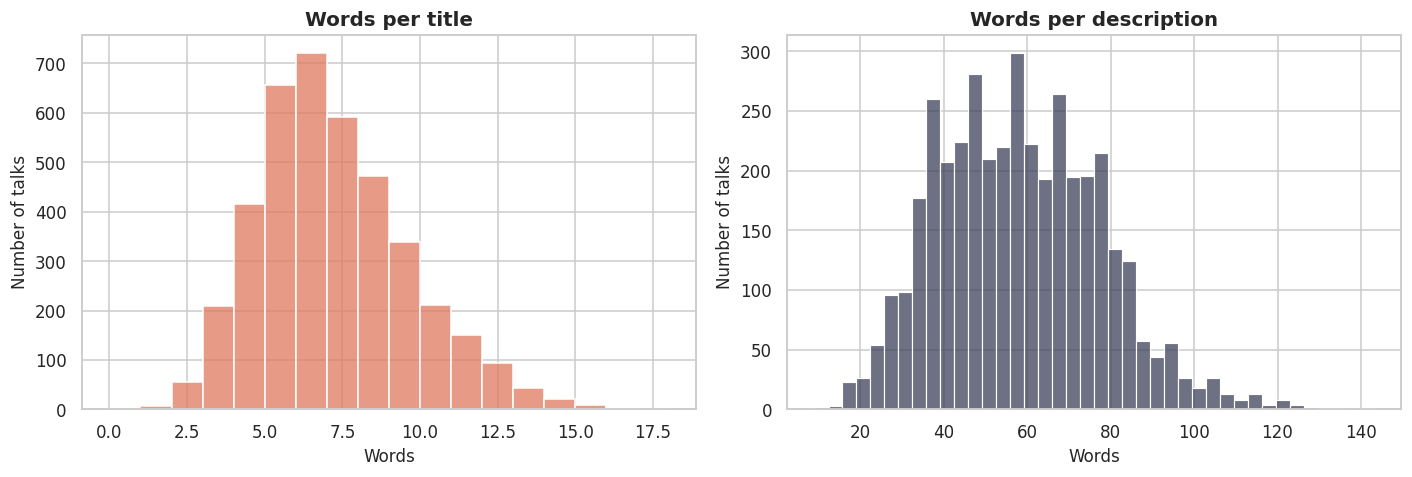

Shortest titles: ['"Tembererana"', '"Clonie"', '"Rollercoaster"']
Longest title  : The real story of Rosa Parks -- and why we need to confront myths about black history
Shortest description: A happy song about global warming, from Jill Sobule.

Talks with the shortest transcripts:


,title,transcript_words
0,"A dance in a hurricane of paper, wind and light",2
1,My magic moves,3
2,"On violin and cello, ""Passacaglia""",4
3,"Dance, tiny robots!",4
4,An 11-year-old prodigy performs old-school jazz,4


Talks with the longest transcripts:


,title,transcript_words
0,The quest for the coronavirus vaccine,11121
1,It's OK to feel overwhelmed. Here's what to do next,10789
2,What the world can learn from China's response to the coronavirus,10075
3,How we can turn the tide on climate,9841
4,Nationalism vs. globalism: the new political divide,9185


In [43]:
# Histograms of title and description length, plus a few examples (long texts are cut, transcripts are never printed in full)
if has_cols("title", "description"):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.histplot(words["title"], bins=range(0, int(words["title"].max()) + 2), ax=ax[0], color="#e07a5f")
    ax[0].set(title="Words per title", xlabel="Words", ylabel="Number of talks")
    sns.histplot(words["description"], bins=40, ax=ax[1], color="#3d405b")
    ax[1].set(title="Words per description", xlabel="Words", ylabel="Number of talks")
    plt.tight_layout()
    plt.show()

    print("Shortest titles:", df.loc[words["title"].nsmallest(3).index, "title"].tolist())
    print("Longest title  :", df.loc[words["title"].idxmax(), "title"])
    print("Shortest description:", str(df.loc[words["description"].idxmin(), "description"])[:150])

if has_cols("transcript", "title"):
    shortest = df.assign(transcript_words=words["transcript"]).nsmallest(5, "transcript_words")[["title", "transcript_words"]]
    longest = df.assign(transcript_words=words["transcript"]).nlargest(5, "transcript_words")[["title", "transcript_words"]]
    print("\nTalks with the shortest transcripts:")
    display(shortest.reset_index(drop=True))
    print("Talks with the longest transcripts:")
    display(longest.reset_index(drop=True))

### 11.3 Transcript quality and usability
A transcript is useful for a content-based recommender only if it contains enough real speech.
We screen for: very short transcripts, speaking pace that looks wrong, non-speech markers (music symbols, `(Applause)`, `(Laughter)` ...),
duplicates, and talks not spoken in English.  
*The thresholds below (50, 100 and 300 words; 60 words per minute) are simple rules chosen for this screening, not official standards.*

In [44]:
import re

if has_cols("transcript", "transcript_word_count"):
    wc = df["transcript_word_count"]
    tiers = pd.cut(wc, bins=[-1, 49, 299, 999, np.inf],
                   labels=["under 50 words", "50-299 words", "300-999 words", "1000+ words"])
    tier_table = tiers.value_counts().sort_index().to_frame("talks")
    tier_table["percent"] = (tier_table["talks"] / N * 100).round(1)
    display(tier_table)

    text = df["transcript"].astype(str)
    music_symbol = text.str.contains("♪", regex=False)
    tag_pattern = r"\((?:applause|laughter|music|video|audio|singing|cheers|cheering|clapping)\)"
    tag_counts = text.str.count(tag_pattern, flags=re.IGNORECASE)
    print(f"Transcripts containing music-note symbols: {int(music_symbol.sum())} ({pct(music_symbol.sum(), N)}%)")
    print(f"Transcripts containing (Applause)/(Laughter)/(Music)-style tags: {int((tag_counts > 0).sum())} ({pct((tag_counts > 0).sum(), N)}%)")
    print(f"Total such tags: {int(tag_counts.sum()):,} (median {tag_counts.median():.0f} per transcript)")

    if has_cols("words_per_minute"):
        slow = df[df["words_per_minute"] < 60]
        print(f"\nTalks speaking under 60 words per minute: {len(slow)} ({pct(len(slow), N)}%)")
        print(f"Median speaking pace: {df['words_per_minute'].median():.0f} words per minute")
    print(f"Duplicate transcripts: {int(df['transcript'].duplicated().sum())}")
    if has_cols("native_lang"):
        not_en = int((df["native_lang"] != "en").sum())
        print(f"Talks not spoken in English (transcript may be in another language): {not_en} ({pct(not_en, N)}%)")

    usable = int((wc >= 100).sum())
    print(f"\nTranscripts with at least 100 words (treated as usable): {usable:,} ({pct(usable, N)}%)")
    if usable < N:
        print("Talks with weak transcripts can still be recommended using their title, description and topics.")

,talks,percent
transcript_word_count,,
under 50 words,10,0.20
50-299 words,34,0.80
300-999 words,1037,25.90
1000+ words,2924,73.00


Transcripts containing music-note symbols: 11 (0.3%)
Transcripts containing (Applause)/(Laughter)/(Music)-style tags: 3367 (84.1%)
Total such tags: 23,094 (median 4 per transcript)

Talks speaking under 60 words per minute: 50 (1.2%)
Median speaking pace: 148 words per minute
Duplicate transcripts: 0
Talks not spoken in English (transcript may be in another language): 48 (1.2%)

Transcripts with at least 100 words (treated as usable): 3,994 (99.7%)
Talks with weak transcripts can still be recommended using their title, description and topics.


### 11.4 Exploratory `combined_text` (in memory)
Rules used (so missing text never causes errors):
1. Use only the content columns that exist (`title`, `description`, `topics`, `transcript`).
2. Missing values become empty text.
3. In `topics`, the `|` separator is replaced by commas so the tags read like normal words.
4. Extra spaces and line breaks are collapsed into single spaces.
5. The pieces are joined with a space.

The column is created **in memory only**; your CSV is not touched.

In [45]:
def tidy_text(series, is_topics=False):
    """Make a text column safe: NaN -> '', collapse spaces, and turn 'a | b' into 'a, b' for topics."""
    s = series.fillna("").astype(str)
    if is_topics:
        s = s.str.replace("|", ", ", regex=False)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()


content_fields = [c for c in ["title", "description", "topics", "transcript"] if c in df.columns]
if not content_fields:
    print("No text columns available - cannot build combined_text.")
else:
    pieces = {c: tidy_text(df[c], is_topics=(c == "topics")) for c in content_fields}
    combined = pieces[content_fields[0]]
    for c in content_fields[1:]:
        combined = combined + " " + pieces[c]
    df["combined_text"] = combined.str.strip()
    print(f"combined_text built from: {content_fields}")
    print(f"Empty combined_text rows: {int((df['combined_text'] == '').sum())}")

combined_text built from: ['title', 'description', 'topics', 'transcript']
Empty combined_text rows: 0


In [46]:
if "combined_text" in df.columns:
    # Preview only the first 300 characters - never the whole transcript
    for _, r in df.sample(2, random_state=7).iterrows():
        print(f"Talk: {r['title'] if 'title' in df.columns else r.name}")
        print(f"combined_text ({len(r['combined_text']):,} characters): {r['combined_text'][:300]}...\n")

    # How long is combined_text, and how much of it comes from each field?
    lengths = df["combined_text"].str.split().str.len()
    print(f"combined_text length in words: min {lengths.min():,} | median {lengths.median():,.0f} | max {lengths.max():,}")
    share = pd.DataFrame({c: pieces[c].str.len() for c in content_fields})
    share = share.div(share.sum(axis=1).replace(0, np.nan), axis=0).mean() * 100
    print("\nAverage share of combined_text characters contributed by each field (%):")
    print(share.round(1).sort_values(ascending=False).to_string())

Talk: How your "working memory" makes sense of the world
combined_text (9,253 characters): How your "working memory" makes sense of the world "Life comes at us very quickly, and what we need to do is take that amorphous flow of experience and somehow extract meaning from it." In this funny, enlightening talk, educational psychologist Peter Doolittle details the importance -- and limitatio...

Talk: Why veterans miss war
combined_text (11,301 characters): Why veterans miss war Civilians don't miss war. But soldiers often do. Journalist Sebastian Junger shares his experience embedded with American soldiers at Restrepo, an outpost in Afghanistan's Korengal Valley that saw heavy combat. Giving a look at the "altered state of mind" that comes with war, h...



combined_text length in words: min 45 | median 1,846 | max 11,246

Average share of combined_text characters contributed by each field (%):
transcript    93.60
description    4.70
topics         1.10
title          0.50


### 11.5 Why these fields help a content-based recommender
- **Title:** short and specific; gives a quick signal of the talk's subject.
- **Description:** a clean summary, usually free of filler words.
- **Topics:** curated tags that name the subject directly and are easy to compare between talks.
- **Transcript:** contains the full vocabulary of the talk, so it can reveal similarities that title and tags miss.
  It is also much longer than the other fields (see the share table above), so in the modelling stage its influence
  will need to be handled carefully.

**Next stage (not done here):** turn `combined_text` into numeric vectors (for example TF-IDF) and measure similarity between talks.

## 12. Data cleaning and preparation
The data was already cleaned earlier, so we do **not** repeat that work. This section only:
1. confirms missing values and duplicates,
2. standardises the text and removes unnecessary characters,
3. builds `combined_text` from **title, topics, description and transcript**,
4. saves the result as a **new** file, `ted_talks_prepared.csv`. Your `ted_talks_cleaned.csv` is never overwritten.

**Status: COMPLETED**

### 12.1 Missing values and duplicates (quick confirmation)

In [47]:
prep = df[ORIG_COLS].copy()                      # work on a copy; df and the CSV file stay unchanged
print(f"Rows: {len(prep):,} | columns: {prep.shape[1]}")
print(f"Null cells: {int(prep.isna().sum().sum())} | duplicate rows: {int(prep.duplicated().sum())} | "
      f"duplicate talk_id: {int(prep['talk_id'].duplicated().sum())}")
print("(Remember from Section 3: no nulls does not mean no placeholders or substituted values.)")

Rows: 4,005 | columns: 37
Null cells: 0 | duplicate rows: 0 | duplicate talk_id: 0
(Remember from Section 3: no nulls does not mean no placeholders or substituted values.)


### 12.2 Standardise text
Rules (applied only to the prepared copy):
- unify unusual characters (Unicode normalisation, e.g. non-breaking spaces),
- turn control characters and line breaks into spaces, 
- in transcripts, remove music-note symbols and the tags `(Applause)`, `(Laughter)`, `(Music)`, `(Video)`, `(Audio)`, `(Singing)`, `(Cheers)`, `(Cheering)`, `(Clapping)`,
- keep a single space between words and trim the ends,
- put topics in a consistent lower-case `a | b | c` format.

Speech content is **not** removed. Parentheses with other content are kept.

In [48]:
import re
import unicodedata

NON_SPEECH_TAGS = re.compile(r"\((?:applause|laughter|music|video|audio|singing|cheers|cheering|clapping)\)", re.IGNORECASE)

def standardise_text(value, remove_non_speech=False):
    """Return clean text: no NaN, normalised characters, no control characters, single spaces."""
    text = "" if pd.isna(value) else str(value)
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"[\x00-\x1f\x7f]", " ", text)
    if remove_non_speech:
        text = NON_SPEECH_TAGS.sub(" ", text)
        text = text.replace("♪", " ")
    return re.sub(r"\s+", " ", text).strip()

before_words = int(prep["transcript"].astype(str).str.split().str.len().sum())
before_changed = {}
for col in ["title", "description", "about_speakers", "speaker_1", "all_speakers", "occupations", "event", "transcript"]:
    if col in prep.columns:
        cleaned = prep[col].map(lambda v: standardise_text(v, remove_non_speech=(col == "transcript")))
        before_changed[col] = int((cleaned != prep[col].astype(str)).sum())
        prep[col] = cleaned

if "topics" in prep.columns:
    prep["topics"] = prep["topics"].map(lambda v: " | ".join(t.strip().lower() for t in str(v).split("|") if t.strip()))

# derived transcript columns must follow the cleaned transcript
prep["transcript_word_count"] = prep["transcript"].str.split().str.len()
prep["words_per_minute"] = (prep["transcript_word_count"] / prep["duration_min"]).round(1)

print("Rows changed by standardisation (per column):")
display(pd.Series(before_changed, name="rows changed").to_frame())
after_words = int(prep["transcript_word_count"].sum())
print(f"Transcript words before: {before_words:,} | after: {after_words:,} | removed: {before_words - after_words:,} "
      f"({pct(before_words - after_words, before_words)}%)")

Rows changed by standardisation (per column):


,rows changed
title,2
description,20
about_speakers,14
speaker_1,3
all_speakers,3
occupations,0
event,0
transcript,3405


Transcript words before: 7,196,367 | after: 7,172,656 | removed: 23,711 (0.3%)


### 12.3 Build `combined_text`
Order: **title, topics, description, transcript**. Topics change from `a | b` to `a, b` so they read like normal words.
Empty parts are skipped, so missing text never breaks the column.

In [49]:
fields = [c for c in ["title", "topics", "description", "transcript"] if c in prep.columns]

def build_combined(row):
    parts = []
    for c in fields:
        text = row[c]
        if c == "topics":
            text = text.replace(" | ", ", ")
        if text:
            parts.append(text)
    return " ".join(parts)

prep["combined_text"] = prep.apply(build_combined, axis=1)
prep["combined_text_words"] = prep["combined_text"].str.split().str.len()
prep["title_words"] = prep["title"].str.split().str.len()
prep["description_words"] = prep["description"].str.split().str.len()
prep["transcript_quality"] = pd.cut(prep["transcript_word_count"], bins=[-1, 49, 299, 999, np.inf],
                                    labels=["under 50 words", "50-299 words", "300-999 words", "1000+ words"]).astype(str)

print(f"combined_text built from: {fields}")
print(f"Empty combined_text rows: {int((prep['combined_text'] == '').sum())}")
w = prep["combined_text_words"]
print(f"combined_text words: min {w.min():,} | median {w.median():,.0f} | max {w.max():,}")
for _, r in prep.sample(2, random_state=3).iterrows():
    print(f"\nTalk: {r['title']}\n{r['combined_text'][:300]}...")

combined_text built from: ['title', 'topics', 'description', 'transcript']
Empty combined_text rows: 0
combined_text words: min 36 | median 1,832 | max 11,234

Talk: A new way to stop identity theft
A new way to stop identity theft tedx, security, self, technology Bartenders need to know your age, retailers need your PIN, but almost no one actually needs your name -- except for identity thieves. ID expert David Birch proposes a safer approach to personal identification -- a "fractured" approach...

Talk: 5 ways to create stronger connections
5 ways to create stronger connections business, work, relationships In a tech-obsessed culture, it can be difficult to build genuine relationships with people, especially in the workplace. Robert Reffkin shares his tips and tricks for establishing authentic connections on the job. So when was the la...


### 12.4 Validate and save the prepared dataset

In [50]:
OUTPUT_NAME = "ted_talks_prepared.csv"
out_path = csv_path.parent / OUTPUT_NAME
if out_path.resolve() == csv_path.resolve():                 # safety: never overwrite the cleaned dataset
    raise ValueError("Output file would overwrite the cleaned dataset. Choose a different name.")

assert len(prep) == N, "row count changed"
assert prep["combined_text"].ne("").all(), "empty combined_text found"
assert not prep["talk_id"].duplicated().any(), "duplicate talk_id found"

prep.to_csv(out_path, index=False)

# read back a few columns to prove the file is valid
check = pd.read_csv(out_path, usecols=["talk_id", "combined_text", "transcript_quality"])
size_mb = out_path.stat().st_size / 1024 ** 2
print(f"Saved: {out_path}")
print(f"Rows: {len(check):,} | columns in the prepared file: {prep.shape[1]} | file size: {size_mb:,.1f} MB")
print(f"New columns added: {[c for c in prep.columns if c not in ORIG_COLS]}")
print("Original cleaned CSV unchanged:", file_fingerprint(csv_path) == FINGERPRINT_BEFORE)
# In Google Colab you can download the file with:  from google.colab import files; files.download(str(out_path))

Saved: ted_talks_prepared.csv
Rows: 4,005 | columns in the prepared file: 42 | file size: 83.4 MB
New columns added: ['combined_text', 'combined_text_words', 'title_words', 'description_words', 'transcript_quality']
Original cleaned CSV unchanged: True


## 13. Findings, limitations and conclusions
The cells below **generate the findings from the data that was just loaded**, so the numbers always match the dataset.

**Status: COMPLETED**

In [51]:
def line(text):
    print("-", text)

print("DATASET CHARACTERISTICS")
line(f"{N:,} talks and {len(ORIG_COLS)} columns.")
if has_cols("published_date"):
    line(f"Talks were published between {df['published_date'].min().date()} and {df['published_date'].max().date()}.")
if has_cols("native_lang"):
    en = (df["native_lang"] == "en").mean() * 100
    line(f"{en:.1f}% of the talks are spoken in English; {df['native_lang'].nunique()} spoken languages appear in total.")
if has_cols("speaker_1"):
    line(f"{df['speaker_1'].nunique():,} distinct primary speakers; {pct((df['speaker_1'].value_counts() == 1).sum(), df['speaker_1'].nunique())}% of them have only one talk.")

print("\nDATA QUALITY AND CLEANING DECISIONS")
line(f"Pandas null cells: {total_nulls}; duplicate rows: {dup_checks.get('duplicate rows (all columns)', 'n/a')}; "
     f"duplicate talk IDs: {dup_checks.get('duplicate talk_id', 'n/a')}.")
if has_cols("comments_missing"):
    line(f"{int(df['comments_missing'].sum()):,} talks ({pct(df['comments_missing'].sum(), N)}%) have no real comment data; "
         "cleaning filled 0, so these zeros are not genuine and were excluded from comment analysis.")
if "occupations" in df and "about_speakers" in df:
    line(f"Occupation is 'Unknown' for {pct((df['occupations'].astype(str).str.lower() == 'unknown').sum(), N)}% of talks; "
         f"speaker bio for {pct((df['about_speakers'].astype(str).str.lower() == 'unknown').sum(), N)}%.")
if has_cols("recorded_date", "published_date"):
    line(f"{int((df['recorded_date'] > df['published_date']).sum())} talks have a recorded date after their published date.")
if has_cols("transcript_word_count"):
    line(f"{int((df['transcript_word_count'] < 50).sum())} talks have transcripts under 50 words.")

print("\nTOPICS")
if has_cols("topics"):
    line(f"{topic_counts.size:,} distinct topics; the most frequent are " +
         ", ".join(f"{k} ({v:,})" for k, v in top15.head(5).items()) + ".")
    if fmt_tags:
        line(f"Format-style tags among the top 15: {', '.join(fmt_tags)} (they describe how the talk was produced, not its subject).")

print("\nPOPULARITY AND DURATION PATTERNS")
if has_cols("views"):
    line(f"Median views {df['views'].median():,.0f} versus mean {df['views'].mean():,.0f}; skewness {df['views'].skew():.2f}; "
         f"the top 10% of talks hold {top10pct:.1f}% of all views.")
if has_cols("duration_min", "views"):
    line(f"Median duration {df['duration_min'].median():.1f} minutes; Spearman correlation duration-views "
         f"{df['duration_min'].corr(df['views'], method='spearman'):.2f}.")
if has_cols("comments_real", "views"):
    sub = df.dropna(subset=["comments_real"])
    line(f"Spearman correlation comments-views (real data only): {sub['views'].corr(sub['comments_real'], method='spearman'):.2f}.")
if has_cols("published_year", "views"):
    line(f"Spearman correlation publication year-views: {df['published_year'].corr(df['views'], method='spearman'):.2f}.")

print("\nLIMITATIONS CHECKED IN THE DATA")
user_cols = [c for c in df.columns if any(k in c.lower() for k in ("user", "rating", "watch", "session", "like"))]
line("Columns that look like user ratings or watch history: " + (", ".join(user_cols) if user_cols else "none found."))
if has_cols("published_date"):
    line(f"Data ends on {df['published_date'].max().date()}: view counts are a snapshot and the final year is incomplete.")

DATASET CHARACTERISTICS


- 4,005 talks and 37 columns.
- Talks were published between 2006-06-27 and 2020-04-30.
- 98.8% of the talks are spoken in English; 12 spoken languages appear in total.
- 3,274 distinct primary speakers; 87.0% of them have only one talk.

DATA QUALITY AND CLEANING DECISIONS
- Pandas null cells: 0; duplicate rows: 0; duplicate talk IDs: 0.
- 655 talks (16.4%) have no real comment data; cleaning filled 0, so these zeros are not genuine and were excluded from comment analysis.
- Occupation is 'Unknown' for 13.0% of talks; speaker bio for 12.6%.
- 17 talks have a recorded date after their published date.
- 10 talks have transcripts under 50 words.

TOPICS
- 457 distinct topics; the most frequent are science (993), technology (979), culture (680), tedx (581), global issues (574).
- Format-style tags among the top 15: tedx, ted-ed (they describe how the talk was produced, not its subject).

POPULARITY AND DURATION PATTERNS
- Median views 1,375,508 versus mean 2,148,006; skewness 8.19; the t

### Findings from the additional analyses (Sections 4.7 and 5.1 - 12)

In [52]:
def have(*names):
    return all(n in globals() for n in names)

def line(text):
    print("-", text)

print("DATES")
if have("yearly"):
    line(f"Talks were published in {yearly.index.min()}-{yearly.index.max()}; peak year {yearly.idxmax()} ({yearly.max()} talks); "
         f"{yearly.index.max()} is a partial year.")

print("\nTOPICS PER TALK")
if have("per_talk"):
    line(f"Median {per_talk.median():.0f} topics per talk (min {per_talk.min()}, max {per_talk.max()}).")

print("\nSPEAKERS")
if have("all_individuals", "talks_per_speaker", "repeat_speakers"):
    line(f"{main_speakers.nunique():,} main speakers and {all_individuals.nunique():,} individual speakers in total.")
    line(f"{len(repeat_speakers):,} speakers gave 2 or more talks; the most by one speaker is {talks_per_speaker.max()} "
         f"({talks_per_speaker.idxmax()}).")

print("\nLANGUAGES")
if have("native_counts", "avail_counts"):
    line(f"{native_counts.index[0]} is the most common spoken language ({pct(native_counts.iloc[0], N)}% of talks); "
         f"{native_counts.size} spoken languages in total.")
    line(f"{avail_counts.size} subtitle languages exist; the most widely available are "
         + ", ".join(f"{k} ({v / N * 100:.0f}%)" for k, v in avail_counts.head(3).items()) + ".")

print("\nEVENTS AND OCCUPATIONS")
if have("event_counts"):
    line(f"{event_counts.size:,} distinct events; the biggest are " + ", ".join(f"{k} ({v})" for k, v in event_counts.head(3).items()) + ".")
if have("occ_counts"):
    line(f"{occ_counts.size:,} distinct occupations; the most common are " + ", ".join(f"{k} ({v})" for k, v in occ_counts.head(3).items())
         + f"; {pct(unknown_talks, N)}% of talks have no occupation.")

print("\nRELATED TALKS")
if have("total_refs", "found_refs"):
    line(f"{total_refs:,} related-talk references; {pct(found_refs, total_refs)}% point to talks that exist in this dataset; "
         f"{int((found_per_talk > 0).sum()):,} of {N:,} talks have at least one usable related talk.")

print("\nTEXT AND TRANSCRIPTS")
if have("length_table"):
    for f in length_table.index:
        line(f"{f}: median {length_table.loc[f, 'median words']:.0f} words (min {length_table.loc[f, 'min words']}, "
             f"max {length_table.loc[f, 'max words']}); empty: {length_table.loc[f, 'empty']}; "
             f"unusually long: {length_table.loc[f, 'unusually long']}.")
if have("usable", "tag_counts"):
    line(f"{pct(usable, N)}% of transcripts have at least 100 words; {pct((tag_counts > 0).sum(), N)}% contain (Applause)/(Laughter)-style tags "
         "that were removed during preparation.")

print("\nPREPARED DATASET")
if have("prep", "out_path"):
    line(f"Saved {out_path.name} with {len(prep):,} rows and {prep.shape[1]} columns; combined_text is never empty "
         f"(median {prep['combined_text_words'].median():,.0f} words).")

DATES
- Talks were published in 2006-2020; peak year 2019 (702 talks); 2020 is a partial year.

TOPICS PER TALK
- Median 7 topics per talk (min 1, max 33).

SPEAKERS
- 3,274 main speakers and 3,353 individual speakers in total.
- 448 speakers gave 2 or more talks; the most by one speaker is 34 (Alex Gendler).

LANGUAGES
- en is the most common spoken language (98.8% of talks); 12 spoken languages in total.
- 114 subtitle languages exist; the most widely available are en (100%), es (98%), pt-br (97%).

EVENTS AND OCCUPATIONS
- 459 distinct events; the biggest are TED-Ed (556), TED2017 (96), TED2018 (96).
- 1,796 distinct occupations; the most common are author (158), writer (142), entrepreneur (105); 13.0% of talks have no occupation.

RELATED TALKS
- 23,915 related-talk references; 99.5% point to talks that exist in this dataset; 4,004 of 4,005 talks have at least one usable related talk.

TEXT AND TRANSCRIPTS
- title: median 6 words (min 1, max 17); empty: 0; unusually long: 78.
- des

### 13.1 General limitations (apply to any analysis of this dataset)
- **Associations, not causes.** The correlations measure how variables move together; they do not prove why.
- **Snapshot data.** Views and comments describe one moment in time, so older and newer talks have had different exposure.
- **Substituted values.** Some zeros and dates were filled during cleaning; the flag columns must be used to keep them separate from real values.
- **Text quality varies.** Some talks have very little transcript text, and some topic tags describe format rather than subject.
- **No user-interaction information is analysed here.** The check in Section 13 lists whether any user-related columns exist in the file; without them, personalization cannot be learned from user behaviour.

### 13.2 Why a content-based approach is reasonable
Collaborative filtering needs a record of what **users** rated or watched. When that information is unavailable, the only evidence about each talk
is its **content**: title, description, topics and transcript. A content-based recommender compares those texts, so it can recommend talks similar to
one the user already likes - even for brand-new users and brand-new talks (no interaction history needed).
Personalization can then come from the talks a user selects, while this EDA shows that the text fields are available for essentially every talk.
Its weakness is that it only finds *similar* items, so variety needs to be considered later.

### 13.3 Columns useful for content-based recommendations
Completeness is measured as the share of talks with real content (not empty and not `Unknown`).

In [53]:
def real_share(col):
    s = df[col]
    if pd.api.types.is_string_dtype(s) or s.dtype == object:
        text = s.fillna("").astype(str).str.strip()
        return pct(((text != "") & (text.str.lower() != "unknown")).sum(), N)
    return pct(s.notna().sum(), N)

column_roles = [
    ("title", "Core text", "Short subject signal; also shown to the user"),
    ("description", "Core text", "Clean summary of the talk"),
    ("topics", "Core text", "Curated tags; easiest to compare between talks"),
    ("transcript", "Core text", "Richest content, but long; weak for very short transcripts"),
    ("speaker_1", "Supporting", "'More from this speaker'"),
    ("occupations", "Supporting", "Speaker field; some Unknown"),
    ("about_speakers", "Supporting", "Extra background text; some Unknown"),
    ("event", "Supporting", "Context; many different events"),
    ("native_lang", "Filter", "Language filter"),
    ("available_lang", "Filter", "Subtitle availability"),
    ("duration_min", "Filter", "Short vs long talk preference"),
    ("related_talk_ids", "Evaluation reference", "TED's own related talks, usable to check recommendations later"),
    ("views", "Popularity (not content)", "Skewed; use log scale if used"),
    ("comments", "Popularity (use with care)", "Many values were filled with 0"),
]
roles = pd.DataFrame([(c, role, why, real_share(c)) for c, role, why in column_roles if c in df.columns],
                     columns=["column", "role", "why it matters", "% talks with real content"]).set_index("column")
display(roles)
print("Prepared column: combined_text (title + topics + description + transcript) is saved in ted_talks_prepared.csv.")

,role,why it matters,% talks with real content
column,,,
title,Core text,Short subject signal; also shown to the user,100.00
description,Core text,Clean summary of the talk,100.00
topics,Core text,Curated tags; easiest to compare between talks,100.00
transcript,Core text,"Richest content, but long; weak for very short transcripts",100.00
speaker_1,Supporting,'More from this speaker',100.00
occupations,Supporting,Speaker field; some Unknown,87.00
about_speakers,Supporting,Extra background text; some Unknown,87.40
event,Supporting,Context; many different events,100.00
native_lang,Filter,Language filter,100.00


Prepared column: combined_text (title + topics + description + transcript) is saved in ted_talks_prepared.csv.


### 13.4 Is the dataset ready for recommendation-model development?
The checks below are calculated from the data. A check is **PASS** or **ATTENTION** (still usable, but must be handled in the next stage).
The usable-transcript threshold of 95% is our own rule of thumb.

In [54]:
usable_share = pct((df["transcript_word_count"] >= 100).sum(), N) if "transcript_word_count" in df else 0
topics_empty = int(is_blank(df["topics"]).sum()) if "topics" in df else N
format_tags_found = [t for t in topic_counts.index if t.startswith("ted")] if "topic_counts" in globals() else []
comments_filled = int(df["comments_missing"].sum()) if "comments_missing" in df else None
unknown_occ_pct = pct((df["occupations"].astype(str).str.lower() == "unknown").sum(), N) if "occupations" in df else None
related_cov = pct((found_per_talk > 0).sum(), N) if "found_per_talk" in globals() else None
combined_empty = int((prep["combined_text"] == "").sum()) if "prep" in globals() else None

checks = [  # (check, result, passed?, critical?)
    ("No duplicate talk IDs or rows", f"{dup_checks.get('duplicate talk_id')} / {dup_checks.get('duplicate rows (all columns)')}",
     dup_checks.get("duplicate talk_id") == 0 and dup_checks.get("duplicate rows (all columns)") == 0, True),
    ("Every talk has topics", f"{topics_empty} talks without topics", topics_empty == 0, True),
    ("combined_text is never empty", f"{combined_empty} empty rows", combined_empty == 0, True),
    ("At least 95% of transcripts are usable (100+ words)", f"{usable_share}%", usable_share >= 95, True),
    ("No substituted comment values", f"{comments_filled} talks", comments_filled == 0, False),
    ("No unknown occupations", f"{unknown_occ_pct}% of talks", unknown_occ_pct == 0, False),
    ("No format-style topic tags", ", ".join(format_tags_found) if format_tags_found else "none", not format_tags_found, False),
    ("Most talks have a usable related talk (for evaluation)", f"{related_cov}% of talks", related_cov is not None and related_cov >= 95, False),
]
readiness = pd.DataFrame([{"check": c, "result": r, "status": "PASS" if ok else "ATTENTION", "critical": crit}
                          for c, r, ok, crit in checks])
display(readiness)

critical_failed = readiness[readiness["critical"] & (readiness["status"] != "PASS")]
if critical_failed.empty:
    print("\nVERDICT: the dataset is READY for content-based recommendation development (critical checks passed).")
else:
    print("\nVERDICT: NOT YET ready. Fix first:", ", ".join(critical_failed["check"]))
attention = readiness[readiness["status"] == "ATTENTION"]
if len(attention):
    print("Remaining limitations to handle in the next stage:")
    for _, r in attention.iterrows():
        print(f" - {r['check']}: {r['result']}")
print("This data has no user ratings or watch histories, so only content-based methods can be built from it.")

,check,result,status,critical
0,No duplicate talk IDs or rows,0 / 0,PASS,True
1,Every talk has topics,0 talks without topics,PASS,True
2,combined_text is never empty,0 empty rows,PASS,True
3,At least 95% of transcripts are usable (100+ words),99.7%,PASS,True
4,No substituted comment values,655 talks,ATTENTION,False
5,No unknown occupations,13.0% of talks,ATTENTION,False
6,No format-style topic tags,"tedx, ted-ed, ted fellows, tedmed, ted prize, ted residency, tedyouth, ted e...",ATTENTION,False
7,Most talks have a usable related talk (for evaluation),100.0% of talks,PASS,False



VERDICT: the dataset is READY for content-based recommendation development (critical checks passed).
Remaining limitations to handle in the next stage:
 - No substituted comment values: 655 talks
 - No unknown occupations: 13.0% of talks
 - No format-style topic tags: tedx, ted-ed, ted fellows, tedmed, ted prize, ted residency, tedyouth, ted en español, tednyc, ted books, ted connects
This data has no user ratings or watch histories, so only content-based methods can be built from it.


## 14. Final EDA summary (for the mentor)

**Status: COMPLETED**

In [55]:
summary_rows = [("Talks (rows)", f"{N:,}"), ("Columns", len(ORIG_COLS)),
                ("Pandas null cells", total_nulls),
                ("Duplicate rows / talk IDs", f"{dup_checks.get('duplicate rows (all columns)', 'n/a')} / {dup_checks.get('duplicate talk_id', 'n/a')}")]
if has_cols("comments_missing"):
    summary_rows.append(("Talks with substituted (filled) comments", f"{int(df['comments_missing'].sum()):,} ({pct(df['comments_missing'].sum(), N)}%)"))
if has_cols("views"):
    summary_rows += [("Median / mean views", f"{df['views'].median():,.0f} / {df['views'].mean():,.0f}"),
                     ("Share of views held by top 10% of talks", f"{top10pct:.1f}%")]
if has_cols("duration_min"):
    summary_rows.append(("Median duration (min)", f"{df['duration_min'].median():.1f}"))
if has_cols("topics"):
    summary_rows += [("Distinct topics", f"{topic_counts.size:,}"), ("Most common topic", f"{top15.index[0]} ({top15.iloc[0]:,} talks)")]
if "combined_text" in df.columns:
    summary_rows.append(("combined_text built (in memory) from", ", ".join(content_fields)))
summary_rows.append(("User ratings / watch-history columns found", ", ".join(user_cols) if user_cols else "none"))

# Prove the original CSV was not modified
summary_rows.append(("Original CSV unchanged by this notebook", file_fingerprint(csv_path) == FINGERPRINT_BEFORE))
display(pd.DataFrame(summary_rows, columns=["item", "result"]).set_index("item"))

,result
item,
Talks (rows),"4,005"
Columns,37
Pandas null cells,0
Duplicate rows / talk IDs,0 / 0
Talks with substituted (filled) comments,655 (16.4%)
Median / mean views,"1,375,508 / 2,148,006"
Share of views held by top 10% of talks,41.3%
Median duration (min),12.3
Distinct topics,457


### 14.1 Completion checklist (requested analysis and where it is in this notebook)
| # | Requested analysis | Section | Status |
|---|---|---|---|
| 1 | Topic analysis (common topics, topics per talk, bar chart) | 5, 5.1 | COMPLETED |
| 2 | Speaker analysis (unique speakers, repeat speakers, top 10 chart) | 6 | COMPLETED |
| 3 | Text analysis (word counts, empty / short / long texts, transcript quality) | 11.1 - 11.3 | COMPLETED |
| 4 | Views analysis (statistics, top 10, histogram, outliers) | 4.1, 4.2 | COMPLETED |
| 5 | Duration analysis (statistics, validity check, histogram) | 4.3 | COMPLETED |
| 6 | Date analysis (datetime, range, yearly counts, trend line) | 4.4, 4.7 | COMPLETED |
| 7 | Language analysis (native and available languages, consistency) | 7 | COMPLETED |
| 8 | Event and occupation analysis (top lists and charts) | 8 | COMPLETED |
| 9 | Comments analysis (statistics, top talks, distribution, outliers, `comments_missing`) | 4.6 | COMPLETED |
| 10 | Related talks analysis (counts, ID check, evaluation idea) | 9 | COMPLETED |
| 11 | Data cleaning and preparation (`combined_text`, new CSV saved) | 12 | COMPLETED |
| 12 | Final findings (summary, useful columns, readiness, limitations) | 13, 14 | COMPLETED |

### Recommended next steps (suggestions, not results of this EDA)
1. Decide how to treat the substituted comment values (keep `comments_missing` as a feature or avoid `comments`).
2. Decide whether format-style topic tags should be kept for similarity.
3. Prepare `combined_text` (possibly with extra text cleaning) for vectorisation.
4. Build and evaluate the content-based recommender in the next notebook/stage.